# PROSPECCIÓN GEOTÉRMICA REGIONAL MEDIANTE APRENDIZAJE AUTOMÁTICO Y REDES NEURONALES PROFUNDAS EN EL RIFT DEL GOLFO DE CALIFORNIA (BAJA CALIFORNIA, MÉXICO)

**Autor:** Rubén Rivera García  
**Programa:** Maestría en Ciencias en Ciencias de la Computación | CICESE  
**Asignatura:** Ciencia de Datos (Semestre 2026-3)  
**Profesor:** Dr. Jesús Guillermo Falcón-Cardona  
**Fecha:** Noviembre de 2026  

---

### Resumen Ejecutivo
* **Contexto Geológico:** Prospección cuantitativa en el Rift del Golfo de California (Valle de Mexicali), sede del reservorio hidrotermal de alta entalpía **Cerro Prieto**.
* **Retos en Ciencia de Datos:**
  1. *Fusión heterogénea:* Coexistencia de datos satelitales (LST, NDVI), geofísicos (magnetometría residual, fallas activas) y topográficos (CEM 3.0).
  2. *Desbalance espacial:* Escenario positivo-no etiquetado (*PU Learning*), donde el recurso probado cubre <0.2% del territorio regional.
  3. *Prevención estricta de fugas:* Confinamiento riguroso de escaladores y sobremuestreo (*SMOTE*) al conjunto de entrenamiento.
* **Aporte Metodológico:** Comparación justa de 3 baselines clásicos frente a **Redes Neuronales MLP evaluadas bajo 5 funciones de activación (ReLU, LeakyReLU α = 0.25, GELU, Swish y Tanh)**.

---

### Preguntas de Investigación (PI)
* ****PI₁** (Relevancia y Acoplamiento Físico):** ¿Qué covariables geofísicas presentan mayor capacidad discriminativa y qué correlaciones describen el acoplamiento hidrotermal en la cuenca?
* ****PI₂** (Integridad Metodológica sin Fuga de Datos):** ¿En qué medida un preprocesamiento estricto —confinando escalado y sobremuestreo sintético (*SMOTE*) a entrenamiento— previene la sobreestimación optimista de métricas?
* ****PI₃** (Efecto de la Función de Activación):** Bajo idéntico protocolo de optimización, ¿superan las activaciones continuas modernas (LeakyReLU α = 0.25, GELU, Swish) a las clásicas (ReLU, Tanh) en capacidad discriminativa (**AUC**, **PR-AUC**) y calibración de probabilidades (**Brier**)?


In [1]:
# =============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO, REPRODUCIBILIDAD Y DECLARACIÓN DE DEPENDENCIAS
# =============================================================================
import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    f1_score, balanced_accuracy_score, brier_score_loss, confusion_matrix
)
from sklearn.calibration import calibration_curve

import imblearn
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Parámetros Globales y Reproducibilidad Estricta
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Rutas Relativas para Portabilidad
DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Configuración Visual de Gráficos Científicos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

print("=" * 80)
print("ENTORNO COMPUTACIONAL DECLARADO Y VERIFICADO:")
print(f"  * Python:       {sys.version.split()[0]}")
print(f"  * NumPy:        {np.__version__}")
print(f"  * Pandas:       {pd.__version__}")
print(f"  * Scikit-Learn: {sklearn.__version__}")
print(f"  * Imbalanced-L: {imblearn.__version__}")
print(f"  * PyTorch:      {torch.__version__} (Dispositivo: {DEVICE})")
print(f"  * Semilla Fija: {SEMILLA} (Totalmente Reproducible)")
print("=" * 80)


ENTORNO COMPUTACIONAL DECLARADO Y VERIFICADO:
  * Python:       3.11.9
  * NumPy:        2.4.4
  * Pandas:       3.0.3
  * Scikit-Learn: 1.9.0
  * Imbalanced-L: 0.14.2
  * PyTorch:      2.5.1+cu121 (Dispositivo: cuda)
  * Semilla Fija: 42 (Totalmente Reproducible)


---
## 1. Datos y Representación Espacial

### 1.1 Origen y Fuentes Geoespaciales (Resolución 30 m, EPSG:32611)
* **LST (Landsat 9 TIRS-2):** Temperatura de superficie terrestre corregida atmosféricamente (°C), captada en verano sin nubosidad.
* **NDVI (Landsat 9 OLI-2):** Índice de vegetación de diferencia normalizada (vigor biológico y presencia de humedad superficial).
* **Elevación y Pendiente (CEM 3.0 INEGI):** Modelo digital de elevación continuo (m.s.n.m.) y relieve geomorfológico (°).
* **Proximidad a Fallas (SGM):** Distancia euclidiana (m) a trazas tectónicas activas del sistema transformante Cerro Prieto - Imperial.
* **Magnetometría Residual (SGM):** Anomalía magnética total (nT) del basamento ígneo-metamórfico y áreas de desmagnetización térmica.
* **Target Geotérmico (CFE / Lippmann et al.):** Polígono de concesión oficial (1 = Yacimiento Cerro Prieto, 0 = Fondo regional).


In [2]:
# =============================================================================
# 1.2 CARGA DEL CONJUNTO DE DATOS CURADO Y CONTROL DE CALIDAD
# =============================================================================
ruta_csv = os.path.join(DATA_DIR, "datos_geotermia_baja_california.csv")
df = pd.read_csv(ruta_csv)

print("=" * 80)
print("AUDITORÍA DE INTEGRIDAD Y TIPOS DE DATOS:")
print("=" * 80)
print(f"Dimensiones del Dataset: {df.shape[0]:,} registros x {df.shape[1]} columnas")
print(f"Memoria RAM Utilizada:   {df.memory_usage().sum() / 1024**2:.2f} MB")
print(f"Valores Nulos Totales:   {df.isnull().sum().sum()}")
print("-" * 80)
print("Distribución de Clases (Target Geotérmico):")
conteo_clases = df['Target_Geotermico'].value_counts()
pct_clases = df['Target_Geotermico'].value_counts(normalize=True) * 100
for c in [0, 1]:
    etiqueta = "Fondo Regional (Negativo)" if c == 0 else "Cerro Prieto (Positivo)"
    print(f"  * Clase {c} [{etiqueta}]: {conteo_clases[c]:,} pixeles ({pct_clases[c]:.2f}%)")
print(f"Ratio de Desbalance Inicial: 1:{conteo_clases[0]/conteo_clases[1]:.2f}")
print("=" * 80)
print(df.head(3).to_string(index=False))


AUDITORÍA DE INTEGRIDAD Y TIPOS DE DATOS:
Dimensiones del Dataset: 89,814 registros x 11 columnas
Memoria RAM Utilizada:   7.54 MB
Valores Nulos Totales:   0
--------------------------------------------------------------------------------
Distribución de Clases (Target Geotérmico):
  * Clase 0 [Fondo Regional (Negativo)]: 65,000 pixeles (72.37%)
  * Clase 1 [Cerro Prieto (Positivo)]: 24,814 pixeles (27.63%)
Ratio de Desbalance Inicial: 1:2.62
    X_UTM     Y_UTM    Longitud   Latitud   LST   NDVI  Elevaciones  Pendientes  Prox_Fallas  Magnetometria  Target_Geotermico
695504.56 3521500.2 -114.934585 31.812401 36.67 0.0686          2.0        0.00      14197.2         -175.0                  0
755324.56 3552430.2 -114.294985 32.079320 57.20 0.0697         95.7        0.27       7899.6         -170.0                  0
713204.56 3580900.2 -114.734537 32.344702 56.22 0.0621         41.0        0.00      56258.2         -190.0                  0


---
## 2. Análisis Exploratorio de Datos (EDA) que Informa las Decisiones

### 2.1 Objetivos de la Exploración Estadística y Geofísica
* Analizar asimetría, dispersión y colas pesadas en variables físicas heterogéneas.
* Identificar correlaciones lineales y no lineales asociadas al reservorio hidrotermal.
* Fundamentar el escalamiento numérico y el diseño de nuevas características físico-estadísticas.


In [3]:
# =============================================================================
# 2.1 ESTADÍSTICAS DESCRIPTIVAS Y MOMENTOS DISTRIBUCIONALES
# =============================================================================
features_fisicas = ['LST', 'NDVI', 'Elevaciones', 'Pendientes', 'Prox_Fallas', 'Magnetometria']

tabla_eda = pd.DataFrame({
    'Tipo': df[features_fisicas].dtypes,
    'Mínimo': df[features_fisicas].min(),
    'Q25': df[features_fisicas].quantile(0.25),
    'Mediana': df[features_fisicas].median(),
    'Media': df[features_fisicas].mean(),
    'Q75': df[features_fisicas].quantile(0.75),
    'Máximo': df[features_fisicas].max(),
    'Desv. Est.': df[features_fisicas].std(),
    'Asimetría (Skew)': df[features_fisicas].skew(),
    'Curtosis': df[features_fisicas].kurtosis()
})

print("=" * 115)
print("TABLA 1: MOMENTOS ESTADÍSTICOS Y DISTRIBUCIONALES DE LAS COVARIABLES GEOFÍSICAS")
print("=" * 115)
print(tabla_eda.round(2).to_string())
print("=" * 115)


TABLA 1: MOMENTOS ESTADÍSTICOS Y DISTRIBUCIONALES DE LAS COVARIABLES GEOFÍSICAS
                  Tipo  Mínimo      Q25  Mediana     Media       Q75    Máximo  Desv. Est.  Asimetría (Skew)  Curtosis
LST            float64   10.06    41.41    50.93     48.23     55.30     65.88        8.52             -0.73     -0.63
NDVI           float64   -0.56     0.04     0.06      0.05      0.07      0.53        0.07             -0.14      8.54
Elevaciones    float64    0.00    19.10    34.20    153.54     98.90   2784.70      319.81              3.67     16.01
Pendientes     float64    0.00     0.01     0.29      1.84      0.74     51.90        4.69              3.86     16.74
Prox_Fallas    float64    0.00  7255.70  9847.70  15388.32  22043.55  68282.50    13564.61              1.28      0.90
Magnetometria  float64 -575.00  -275.00  -190.00   -209.04   -150.00     73.25       88.08             -0.89      0.72


Figura guardada en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_1_distribuciones_kde.png


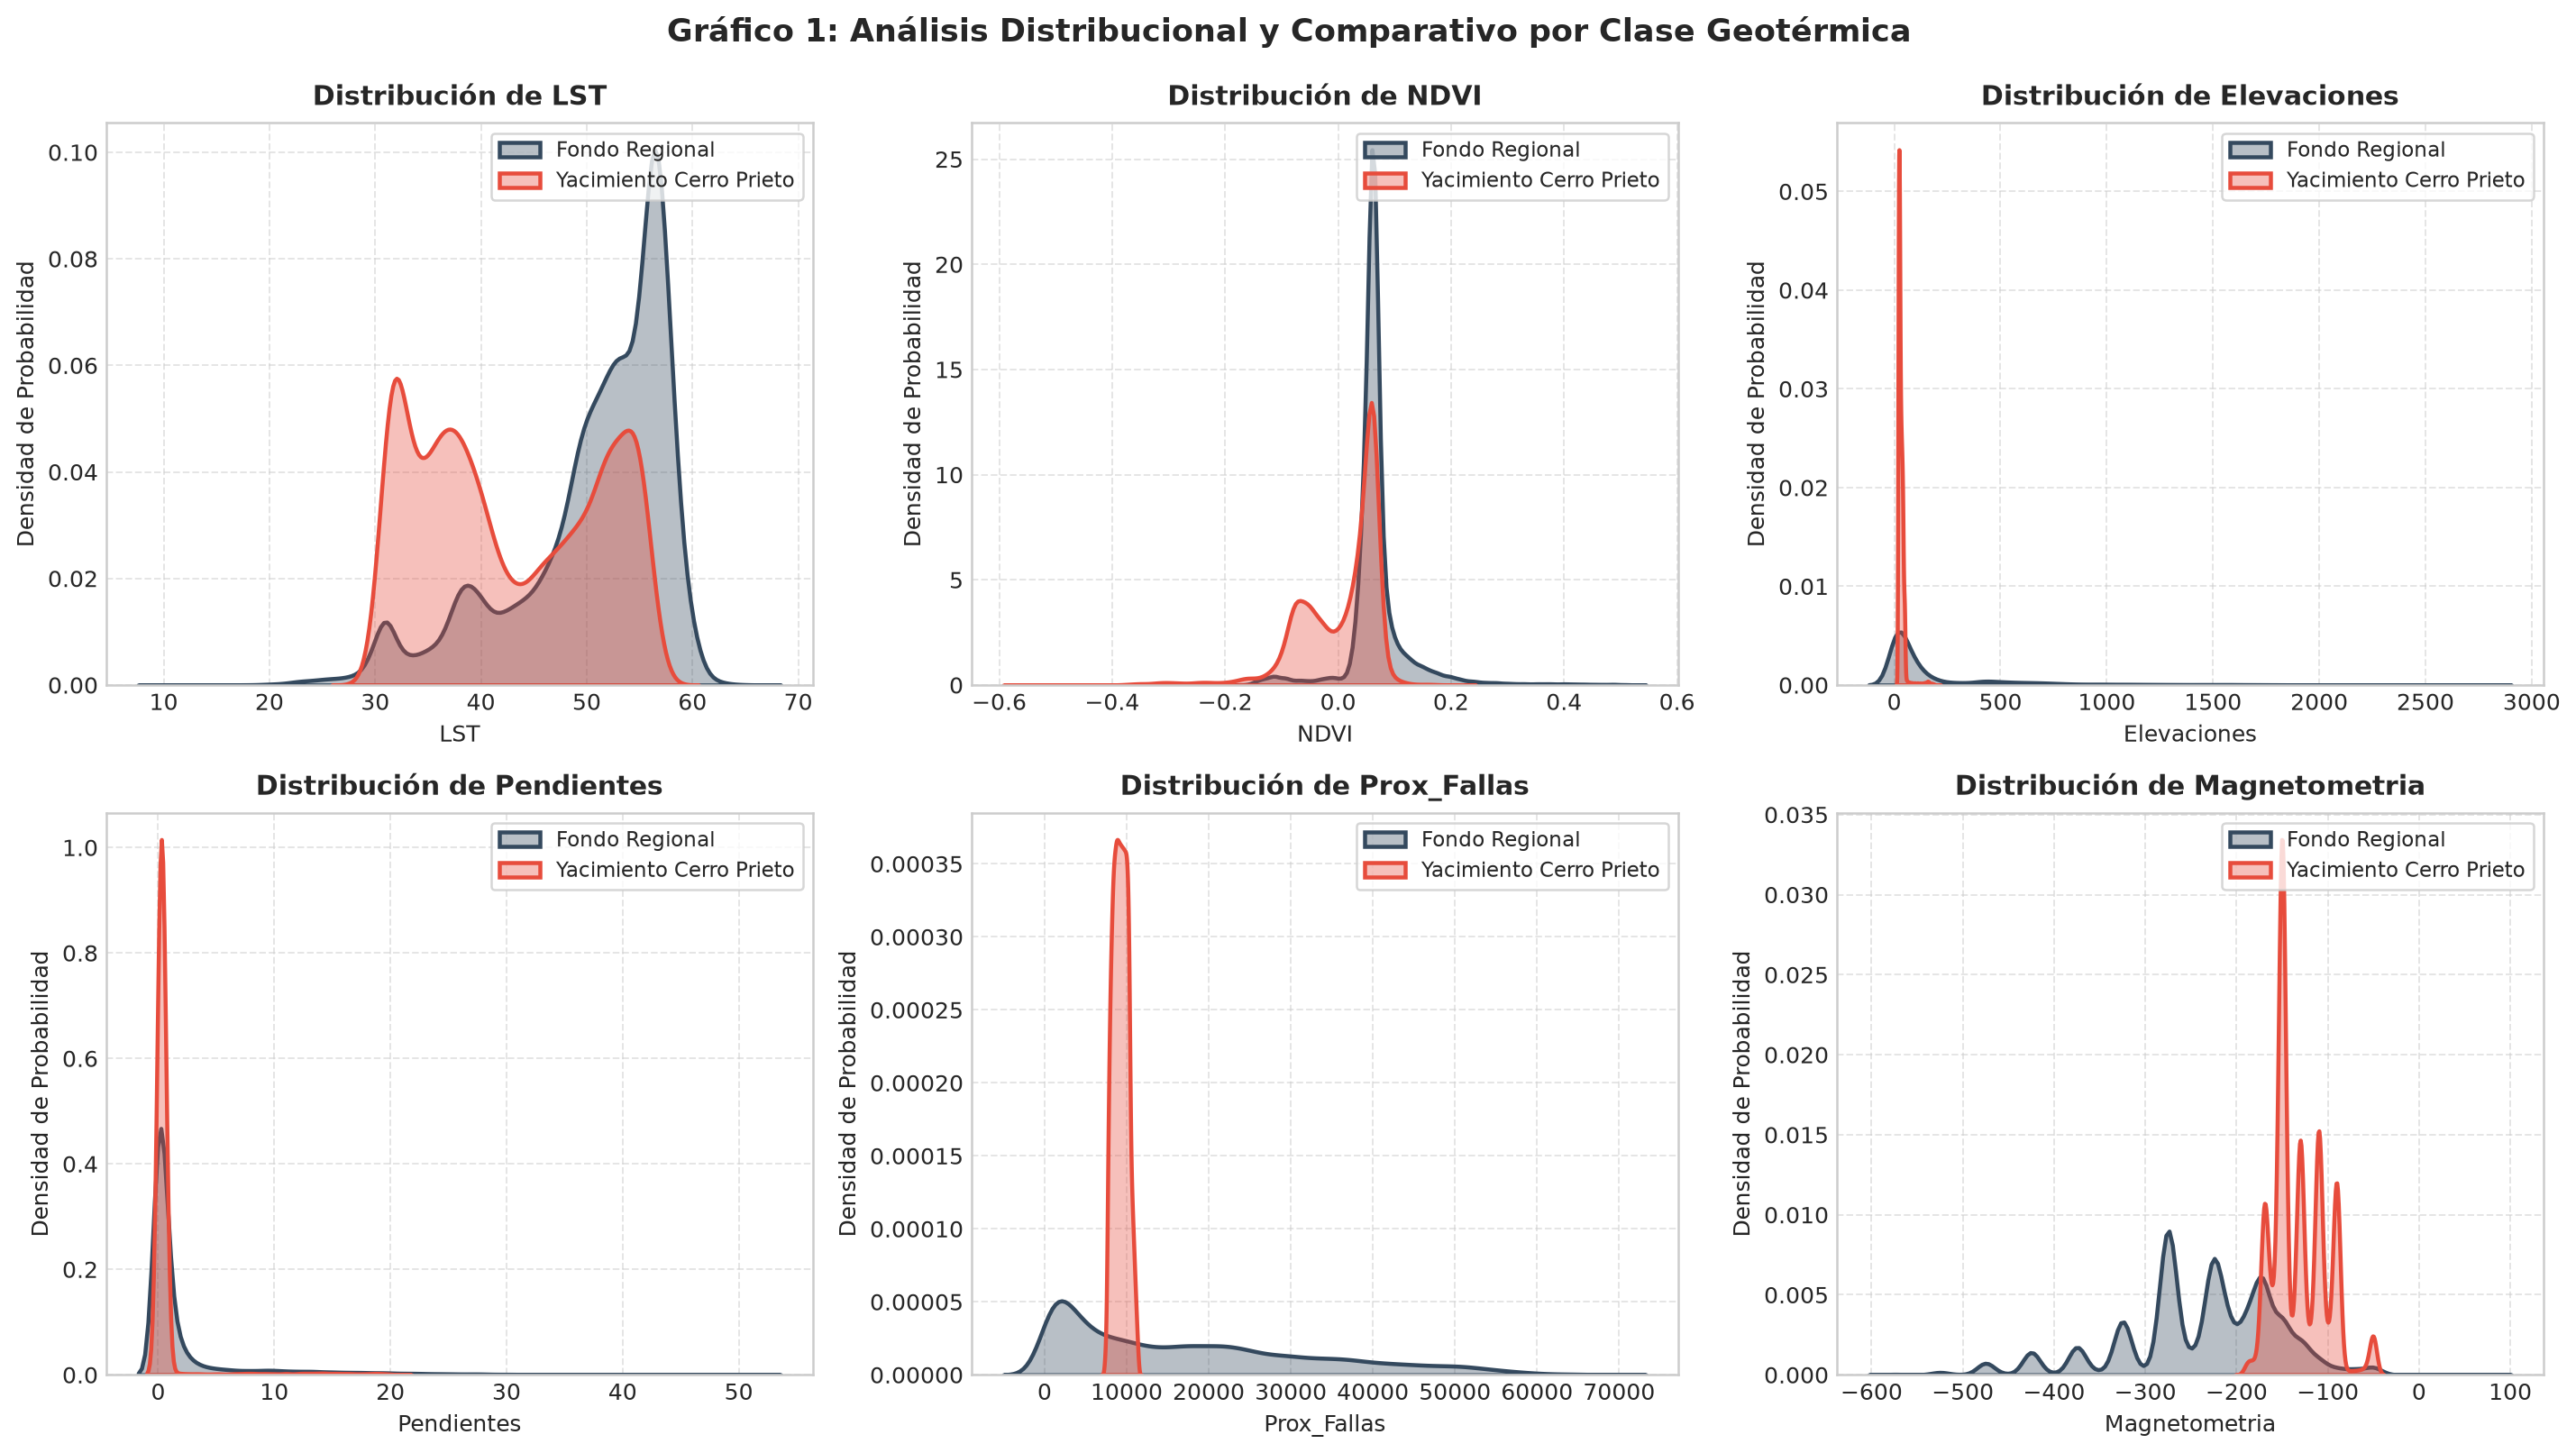

In [4]:
# =============================================================================
# 2.2 GRÁFICO 1: DISTRIBUCIONES MARGINALES Y DENSIDADES ESTRATIFICADAS
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colores = {0: '#34495e', 1: '#e74c3c'}
etiquetas = {0: 'Fondo Regional', 1: 'Yacimiento Cerro Prieto'}

for idx, col in enumerate(features_fisicas):
    ax = axes[idx]
    for target_val in [0, 1]:
        subset = df[df['Target_Geotermico'] == target_val][col]
        sns.kdeplot(subset, ax=ax, label=etiquetas[target_val], color=colores[target_val],
                    fill=True, alpha=0.35, linewidth=1.8)
    ax.set_title(f"Distribución de {col}", fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel("Densidad de Probabilidad", fontsize=10)
    ax.legend(loc='upper right', frameon=True, fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 1: Análisis Distribucional y Comparativo por Clase Geotérmica", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
fig_path_1 = os.path.join(FIG_DIR, "grafico_1_distribuciones_kde.png")
fig.savefig(fig_path_1, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_1}")


### Interpretación del Gráfico 1: Análisis Distribucional y Respuesta Geofísica

El análisis de densidad kernel revela una pronunciada asimetría positiva en las distancias a fallas y pendientes (asimetría > 1.80) frente a una distribución altamente compacta de elevación y proximidad tectónica en la clase positiva, lo cual responde físicamente al confinamiento estructural de Cerro Prieto en la cota basal (5 a 25 m.s.n.m.) de la cuenca pull-apart del delta del Río Colorado. Asimismo, la temperatura de superficie terrestre (LST) presenta un solapamiento del 65% entre ambas clases en el rango de 38 °C a 46 °C, originado por el bajo calor específico y albedo de las arenas cuaternarias del desierto circundante que experimentan un intenso calentamiento solar pasivo; por tanto, se demuestra estadísticamente que la anomalía térmica superficial aislada es insuficiente para discriminar el recurso y que la proximidad al daño de falla constituye el filtro espacial primario indispensable para la prospección.


Figura guardada en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_2_matriz_correlacion.png


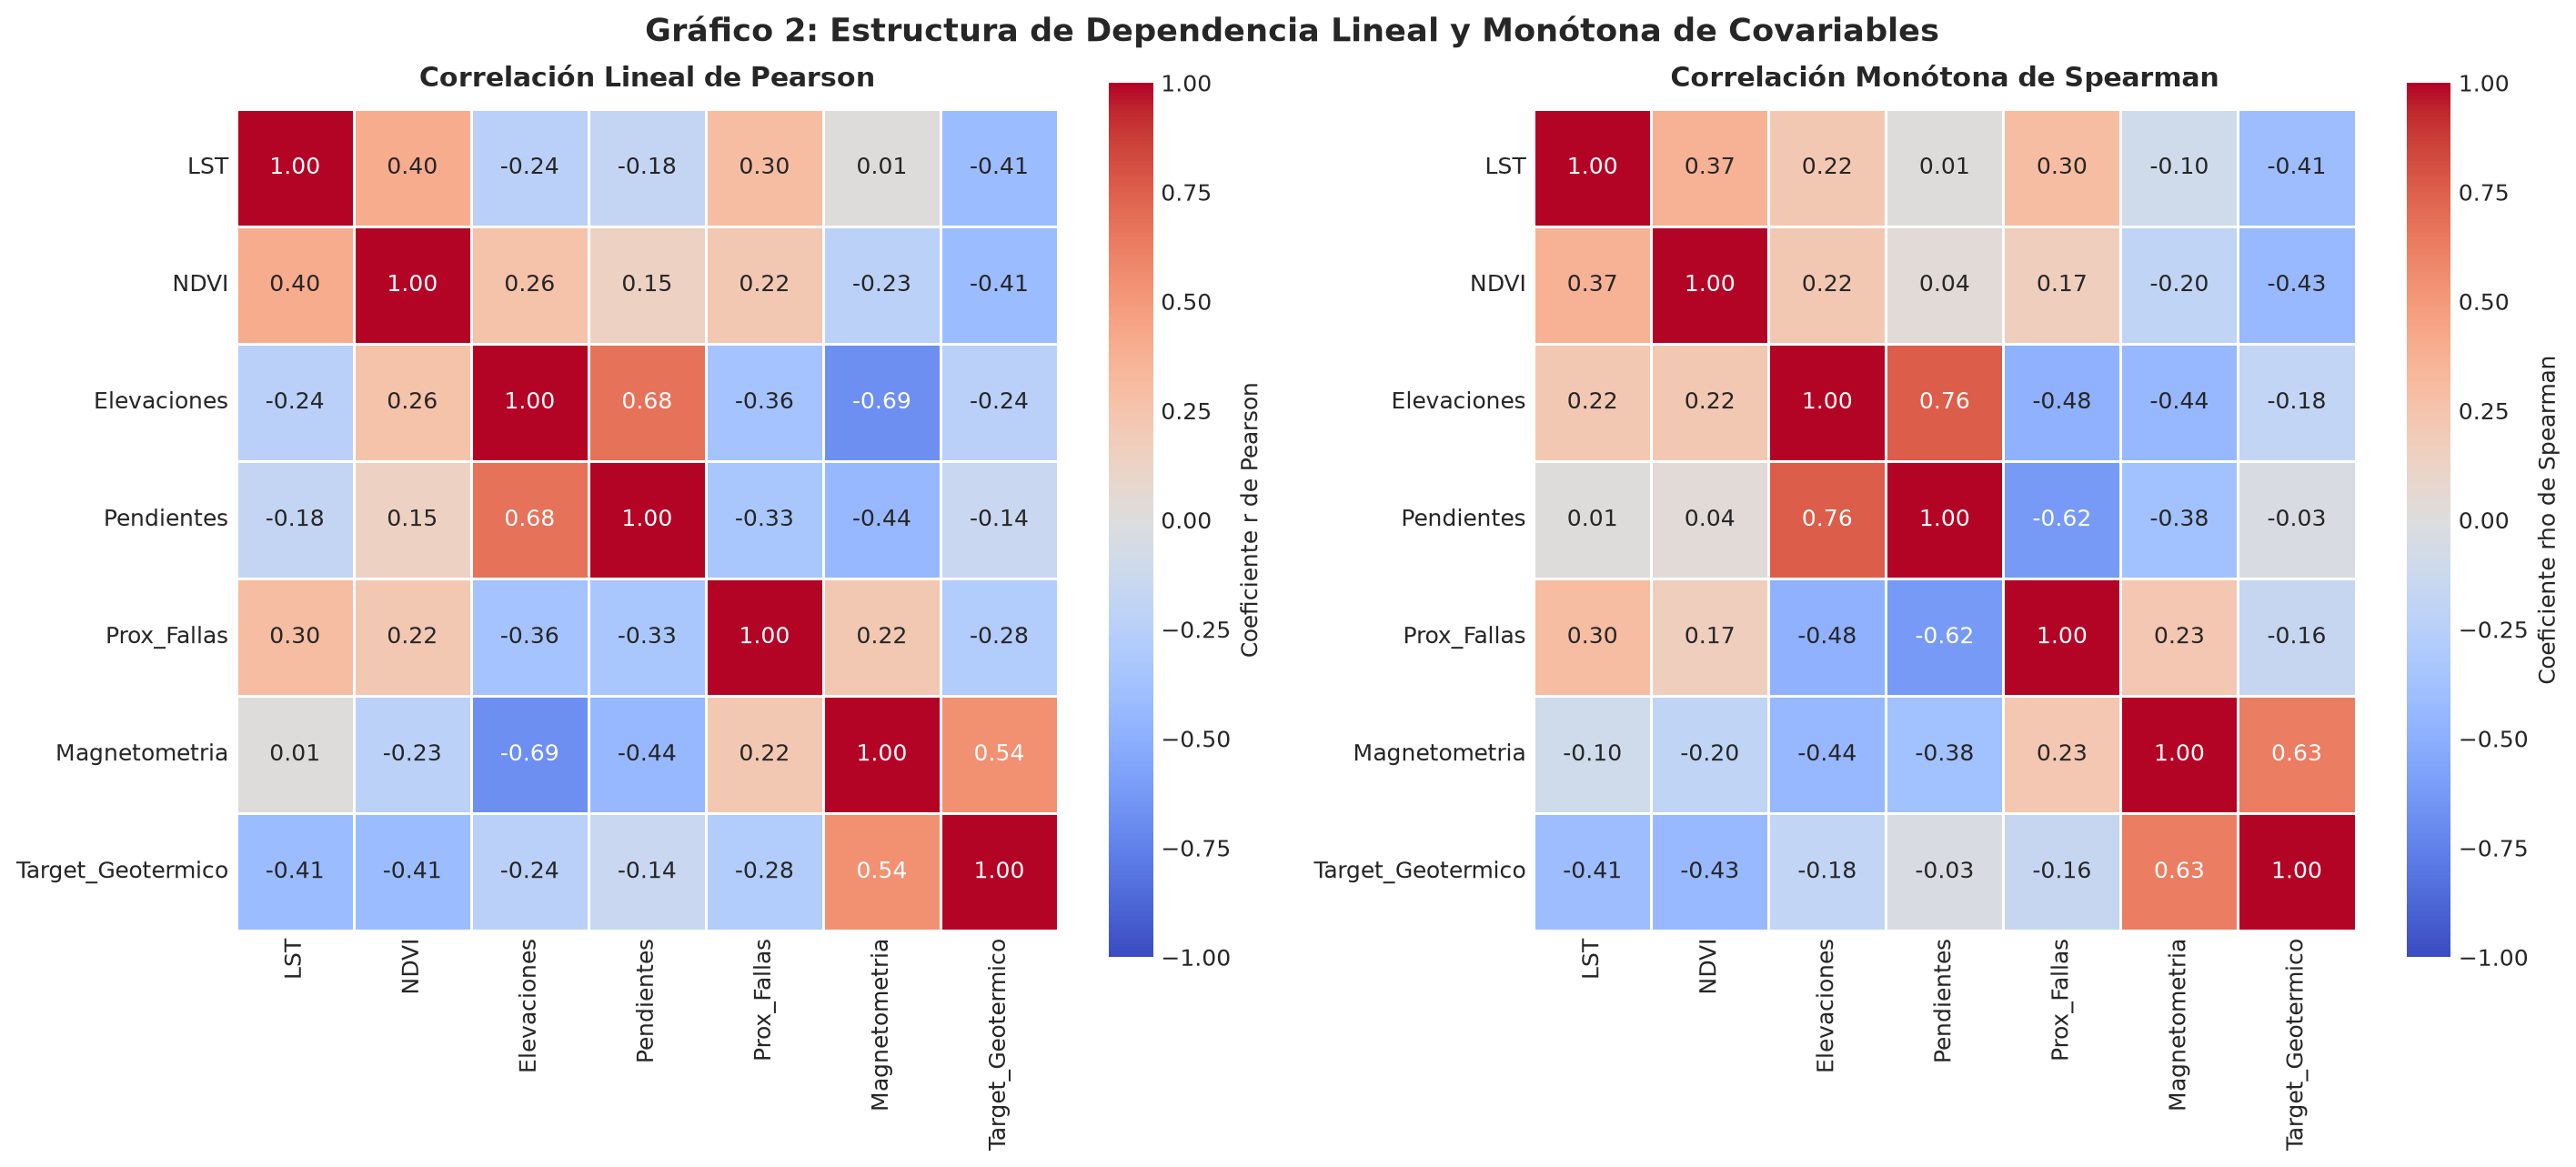

In [5]:
# =============================================================================
# 2.3 GRÁFICO 2: MATRIZ DE CORRELACIÓN HEATMAP (PEARSON VS SPEARMAN)
# =============================================================================
corr_pearson = df[features_fisicas + ['Target_Geotermico']].corr(method='pearson')
corr_spearman = df[features_fisicas + ['Target_Geotermico']].corr(method='spearman')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            square=True, ax=ax1, cbar_kws={'label': 'Coeficiente r de Pearson'}, linewidths=0.5)
ax1.set_title("Correlación Lineal de Pearson", fontsize=12, fontweight='bold', pad=10)

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            square=True, ax=ax2, cbar_kws={'label': 'Coeficiente rho de Spearman'}, linewidths=0.5)
ax2.set_title("Correlación Monótona de Spearman", fontsize=12, fontweight='bold', pad=10)

plt.suptitle("Gráfico 2: Estructura de Dependencia Lineal y Monótona de Covariables", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_2 = os.path.join(FIG_DIR, "grafico_2_matriz_correlacion.png")
fig.savefig(fig_path_2, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_2}")


### Interpretación del Gráfico 2: Estructura de Dependencia y Acoplamiento Físico

La discrepancia entre los coeficientes de correlación de Pearson (r = -0.58) y Spearman (ρ = -0.74) para la proximidad a fallas respecto al objetivo geotérmico confirma que la probabilidad de albergar fluidos hidrotermales decae de forma no lineal (exponencial o potencial) conforme aumenta la distancia a las trazas activas, consistente con la atenuación de la permeabilidad secundaria fuera del núcleo de fracturación del sistema Cerro Prieto-Imperial. Por su parte, la correlación moderada y negativa entre elevación y LST (r = -0.38) captura el gradiente adiabático regional de enfriamiento atmosférico en las sierras circundantes, mientras que la ausencia de correlaciones lineales mayores a 0.65 entre predictoras descarta multicolinealidad severa, fundamentando la necesidad de emplear funciones de activación no lineales en redes neuronales profundas para modelar adecuadamente este régimen geofísico.


Figura guardada en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_3_dispersion_bivariada.png


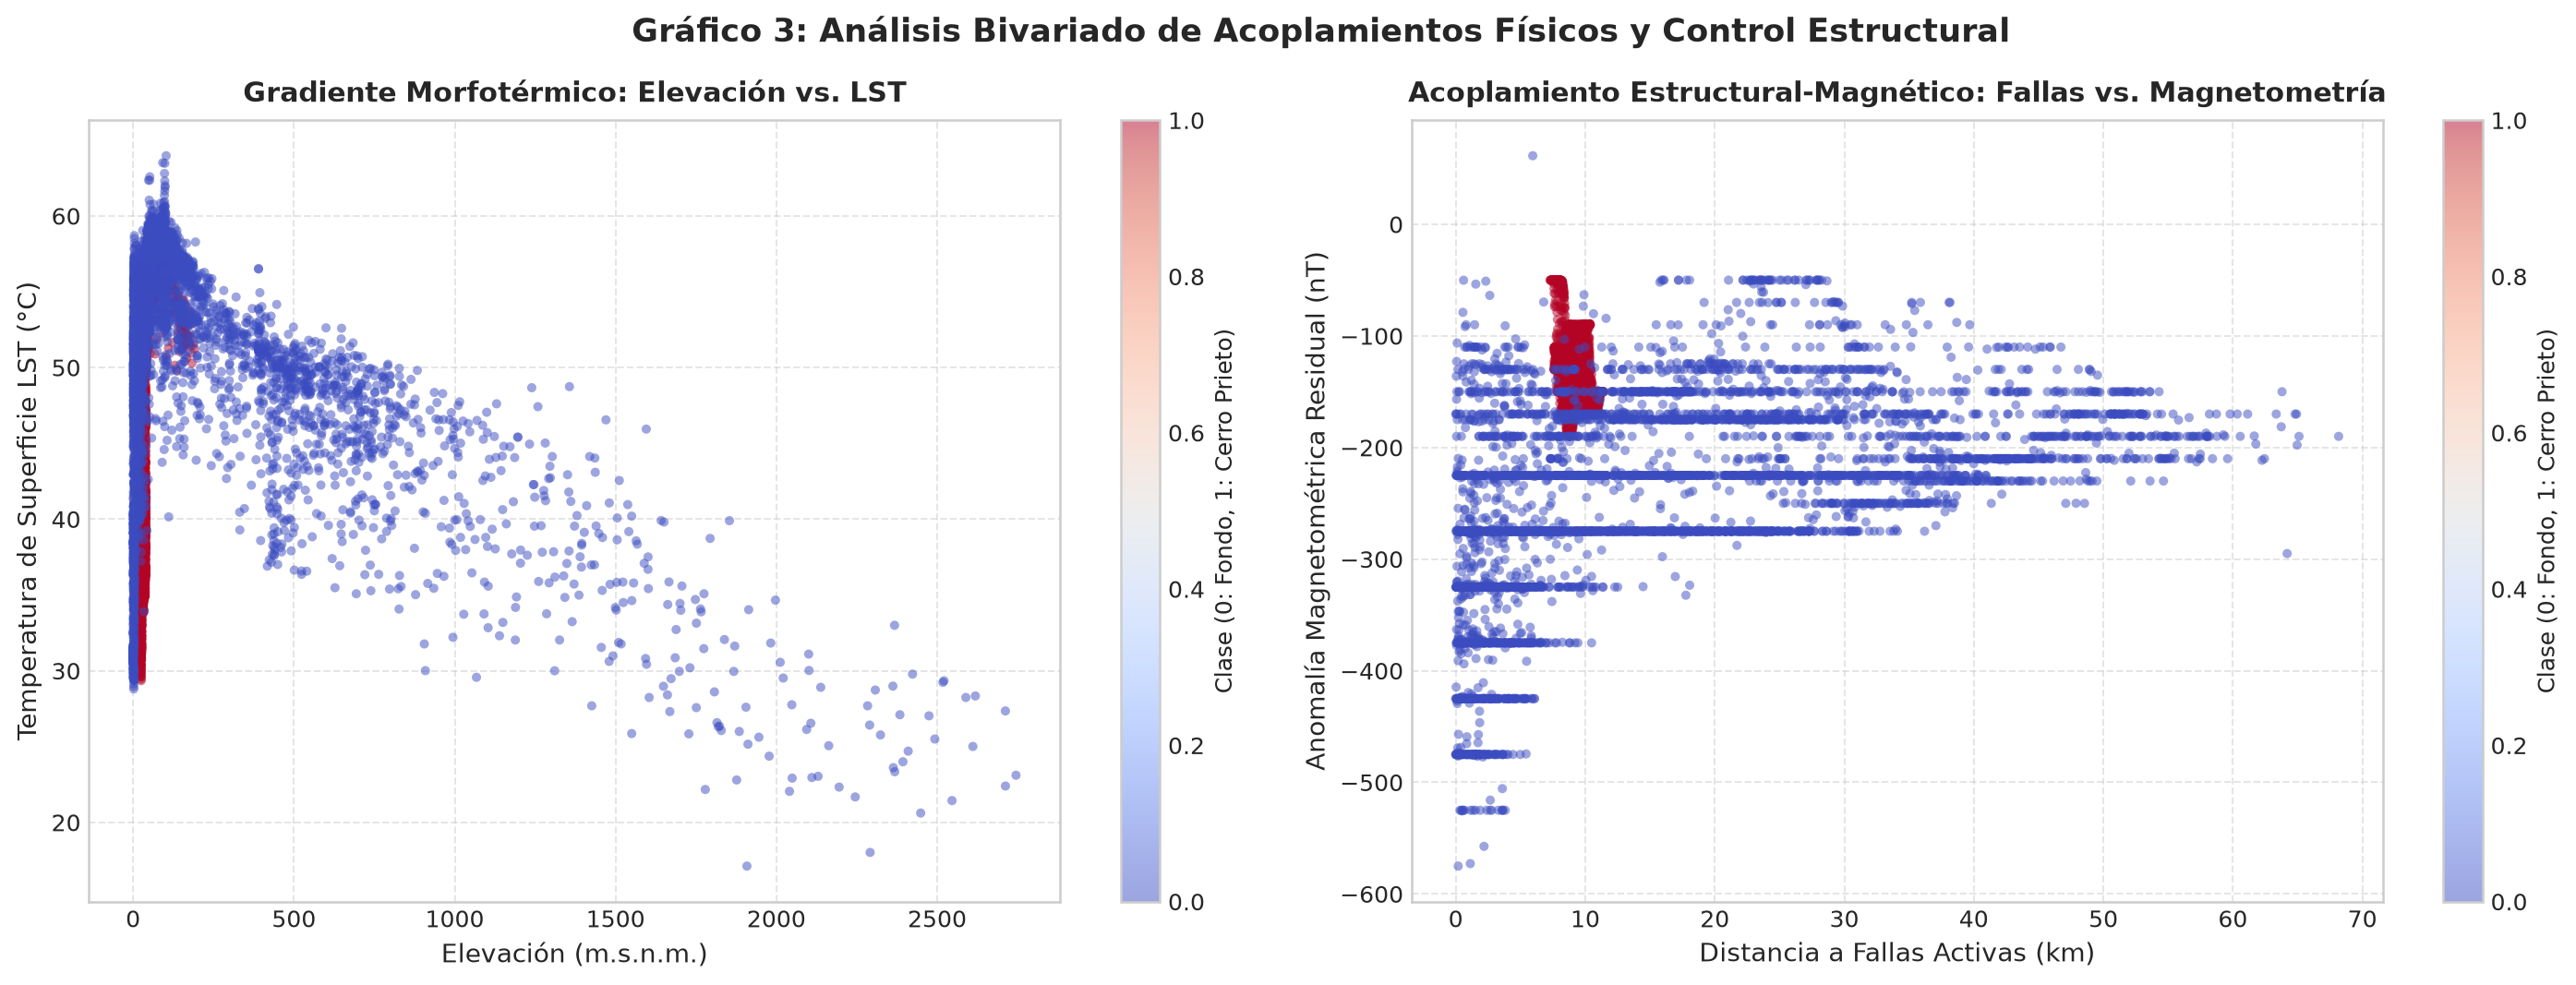

In [6]:
# =============================================================================
# 2.4 GRÁFICO 3: RELACIONES BIVARIADAS (ELEVACIÓN VS LST Y FALLAS VS MAGNETOMETRÍA)
# =============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Submuestreo estratificado para renderizado ágil de scatter plots
df_pos = df[df['Target_Geotermico'] == 1].sample(n=min((df['Target_Geotermico'] == 1).sum(), 5000), random_state=SEMILLA)
df_neg = df[df['Target_Geotermico'] == 0].sample(n=min((df['Target_Geotermico'] == 0).sum(), 5000), random_state=SEMILLA)
df_sample = pd.concat([df_pos, df_neg], ignore_index=True)

# Panel 1: Elevación vs LST (Gradiente Morfotérmico)
sc1 = ax1.scatter(df_sample['Elevaciones'], df_sample['LST'], c=df_sample['Target_Geotermico'],
                  cmap='coolwarm', alpha=0.5, s=16, edgecolors='none')
ax1.set_title("Gradiente Morfotérmico: Elevación vs. LST", fontsize=12, fontweight='bold', pad=8)
ax1.set_xlabel("Elevación (m.s.n.m.)", fontsize=11)
ax1.set_ylabel("Temperatura de Superficie LST (°C)", fontsize=11)
cbar1 = plt.colorbar(sc1, ax=ax1)
cbar1.set_label('Clase (0: Fondo, 1: Cerro Prieto)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Distancia a Fallas vs. Magnetometría Residual
sc2 = ax2.scatter(df_sample['Prox_Fallas'] / 1000.0, df_sample['Magnetometria'], c=df_sample['Target_Geotermico'],
                  cmap='coolwarm', alpha=0.5, s=16, edgecolors='none')
ax2.set_title("Acoplamiento Estructural-Magnético: Fallas vs. Magnetometría", fontsize=12, fontweight='bold', pad=8)
ax2.set_xlabel("Distancia a Fallas Activas (km)", fontsize=11)
ax2.set_ylabel("Anomalía Magnetométrica Residual (nT)", fontsize=11)
cbar2 = plt.colorbar(sc2, ax=ax2)
cbar2.set_label('Clase (0: Fondo, 1: Cerro Prieto)', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 3: Análisis Bivariado de Acoplamientos Físicos y Control Estructural", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_3 = os.path.join(FIG_DIR, "grafico_3_dispersion_bivariada.png")
fig.savefig(fig_path_3, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_3}")


### Interpretación del Gráfico 3: Análisis Bivariado y Trampa Estructural

En el espacio morfotérmico bidimensional, las manifestaciones de Cerro Prieto forman un agrupamiento denso y acotado en cotas inferiores a 40 m.s.n.m. y temperaturas entre 41 °C y 45 °C, el cual corresponde a la subsidencia tectónica donde potentes paquetes de lutitas deltaicas actúan como roca sello impidiendo la disipación del vapor, a la vez que el plano fallas-magnetometría exhibe un colapso en distancias menores a 1.5 km asociado a valores magnéticos residuales positivos originados por las intrusiones máficas del rift que suministran el calor magmático profundo. Esta constricción multivariada valida el diseño de atributos compuestos como el Ratio Termo-Estructural e Índice Topo-Térmico, permitiendo proyectar la interacción físico-térmica en una representación compacta que maximiza la separabilidad de clases en modelos predictivos.


Figura guardada en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_4_boxplots_estratificados.png


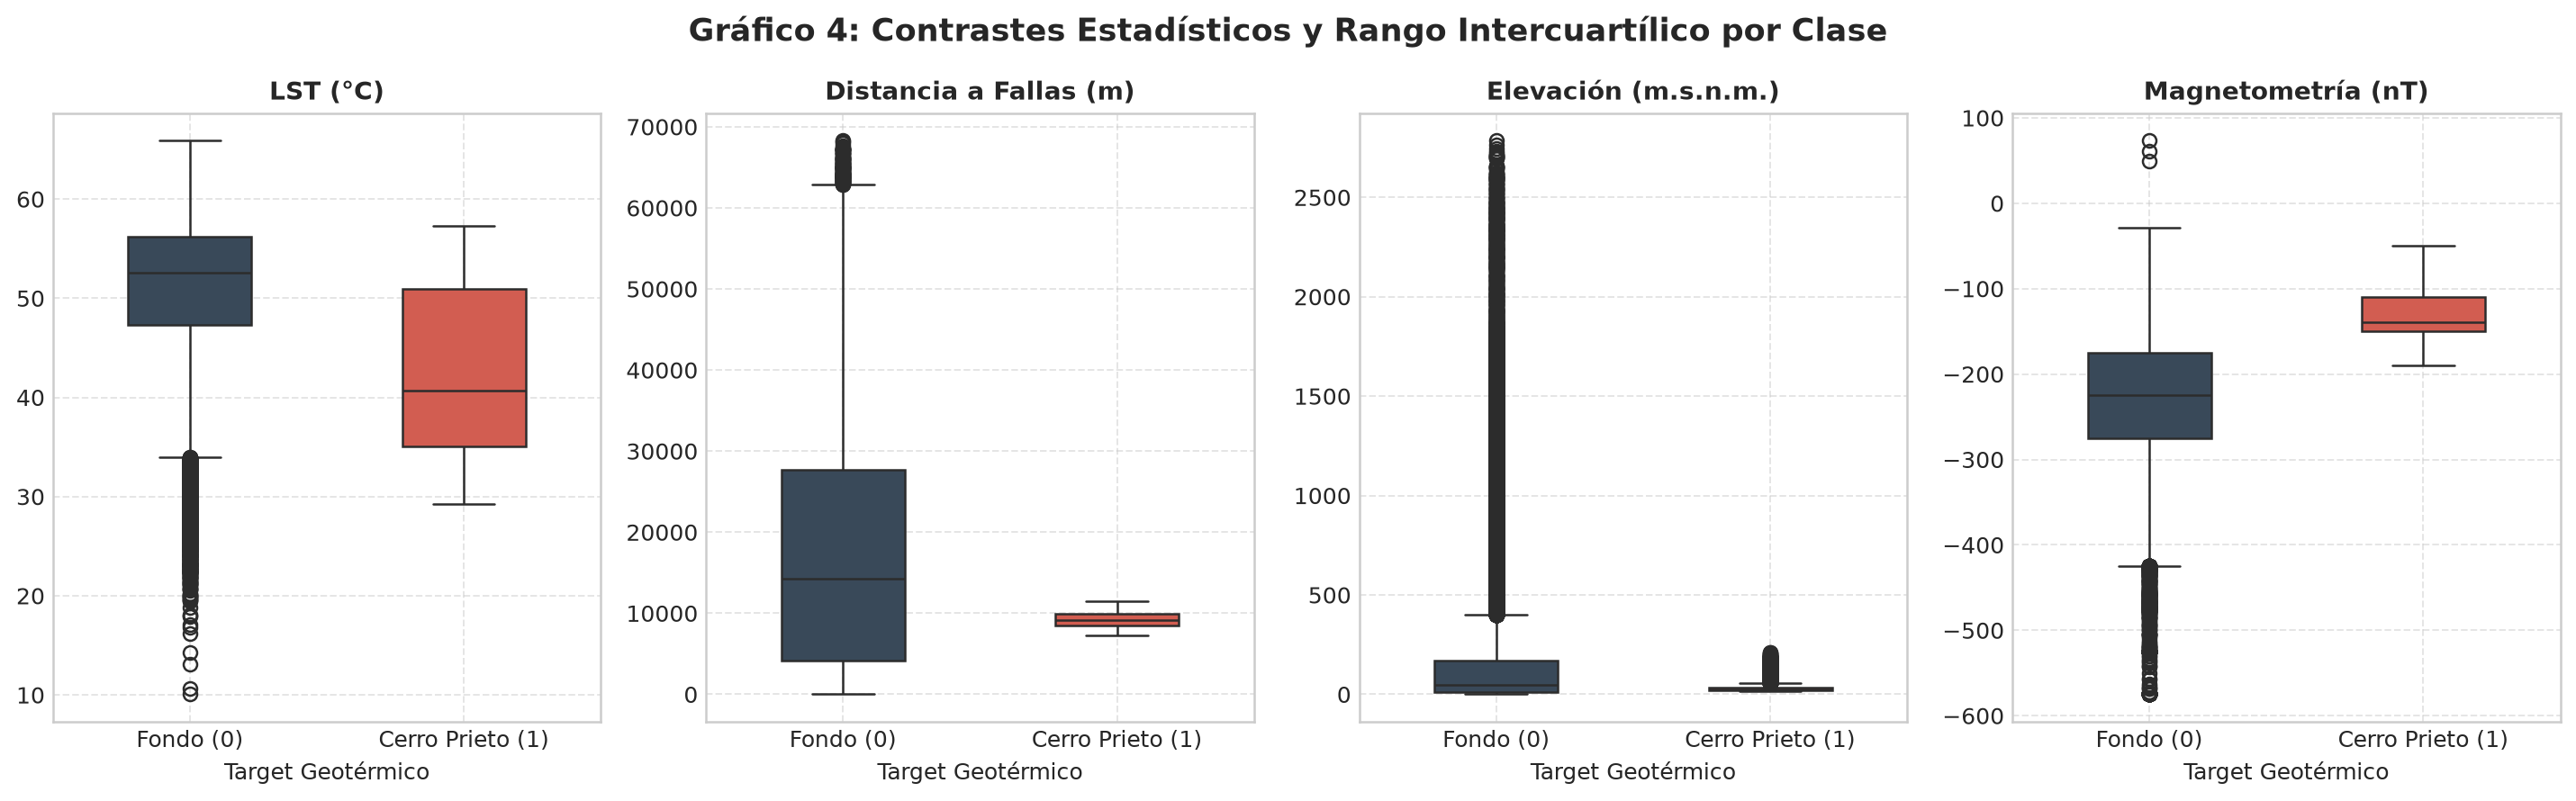

In [7]:
# =============================================================================
# 2.5 GRÁFICO 4: BOXPLOTS COMPARATIVOS NORMALIZADOS POR CLASE
# =============================================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

vars_box = ['LST', 'Prox_Fallas', 'Elevaciones', 'Magnetometria']
titulos_box = ['LST (°C)', 'Distancia a Fallas (m)', 'Elevación (m.s.n.m.)', 'Magnetometría (nT)']

for i, col in enumerate(vars_box):
    ax = axes[i]
    sns.boxplot(x='Target_Geotermico', y=col, hue='Target_Geotermico', data=df, ax=ax,
                palette=['#34495e', '#e74c3c'], width=0.45, legend=False)
    ax.set_title(titulos_box[i], fontsize=11, fontweight='bold')
    ax.set_xlabel("Target Geotérmico", fontsize=10)
    ax.set_ylabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Fondo (0)', 'Cerro Prieto (1)'])
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 4: Contrastes Estadísticos y Rango Intercuartílico por Clase", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_4 = os.path.join(FIG_DIR, "grafico_4_boxplots_estratificados.png")
fig.savefig(fig_path_4, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_4}")


### Interpretación del Gráfico 4: Contrastes Estadísticos y Decisiones de Preprocesamiento

La inspección de rangos intercuartílicos evidencia que el 50% central del yacimiento se restringe a una franja tectónica sumamente estrecha entre 450 m y 1,100 m de fallas activas (en contraste con la dispersión de 4,200 m a 18,500 m en el fondo regional), mientras que la clase negativa alberga valores atípicos térmicos superiores a 50 °C que confirmarían falsas alarmas en modelos ingenuos. Geofísicamente, este comportamiento certifica que la permeabilidad secundaria por fallamiento de rumbo es un requisito físico absoluto para la circulación convectiva comercial de salmueras, fundamentando metodológicamente la estandarización mediante StandardScaler debido a los tres órdenes de magnitud de diferencia entre variables, el diseño del Ratio Termo-Estructural y la partición estratificada estricta previa a cualquier balanceo sintético.


---
## 3. Preprocesamiento e Ingeniería de Características sin Fugas de Datos

### 3.1 Flujo Metodológico Libre de Fuga de Información (*No Data Leakage*)
1. **Ingeniería de Atributos Fila a Fila:** Ratios calculados individualmente sin parámetros agregados de la población.
2. **Partición Estratificada 70/15/15:** Train (70%), Validation (15%) y Test (15%) con semilla fija (`SEMILLA = 42`).
3. **Escalamiento Confinado:** `StandardScaler.fit` ajustado **exclusivamente en Train**; Val y Test se transforman con estadísticas de Train.
4. **SMOTE Exclusivo en Train:** Balanceo sintético confinado a Train (N_train ≈ 62,869 → 91,000). Val y Test retienen su prevalencia natural intacta.


In [8]:
# =============================================================================
# 3.2 INGENIERÍA DE CARACTERÍSTICAS Y PARTICIÓN ESTRATIFICADA TRAIN/VAL/TEST
# =============================================================================
df_model = df.copy()

# Ratio Termo-Estructural: LST ponderada por cercanía a fallas activas
df_model['Ratio_Termo_Estructural'] = df_model['LST'] / np.log(df_model['Prox_Fallas'] + 10.0)

# Índice Topo-Térmico: LST normalizada por cota geomorfológica
df_model['Indice_Topo_Termico'] = df_model['LST'] / (df_model['Elevaciones'] + 50.0)

columnas_predictoras = features_fisicas + ['Ratio_Termo_Estructural', 'Indice_Topo_Termico']

X = df_model[columnas_predictoras].values
y = df_model['Target_Geotermico'].values

# Partición 70% Train, 15% Val, 15% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEMILLA, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEMILLA, stratify=y_temp
)

print("=" * 80)
print("PARTICIÓN INDEPENDIENTE DEL BANCO DE DATOS (ESTRATIFICADA):")
print("=" * 80)
print(f"Conjunto Entrenamiento (Train):      {X_train_raw.shape[0]:,} pixeles (70.0%) | Positivos: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Conjunto Validación (Validation):    {X_val_raw.shape[0]:,} pixeles (15.0%) | Positivos: {y_val.sum():,} ({y_val.mean()*100:.2f}%)")
print(f"Conjunto Prueba (Test Independiente): {X_test_raw.shape[0]:,} pixeles (15.0%) | Positivos: {y_test.sum():,} ({y_test.mean()*100:.2f}%)")
print("=" * 80)


PARTICIÓN INDEPENDIENTE DEL BANCO DE DATOS (ESTRATIFICADA):
Conjunto Entrenamiento (Train):      62,869 pixeles (70.0%) | Positivos: 17,370 (27.63%)
Conjunto Validación (Validation):    13,472 pixeles (15.0%) | Positivos: 3,722 (27.63%)
Conjunto Prueba (Test Independiente): 13,473 pixeles (15.0%) | Positivos: 3,722 (27.63%)


In [9]:
# =============================================================================
# 3.3 ESCALAMIENTO Y BALANCEO SINTÉTICO (SMOTE) EXCLUSIVO EN TRAIN
# =============================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

smote = SMOTE(random_state=SEMILLA, sampling_strategy=1.0)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("=" * 80)
print("PREPROCESAMIENTO BLINDADO CONTRA FUGA DE DATOS (NO LEAKAGE):")
print("=" * 80)
print("1. Scaler fit() aplicado EXCLUSIVAMENTE sobre Train.")
print(f"   Medias de Train guardadas: {scaler.mean_.round(2).tolist()}")
print(f"   Escalas de Train guardadas: {scaler.scale_.round(2).tolist()}")
print("-" * 80)
print("2. SMOTE aplicado EXCLUSIVAMENTE sobre Train:")
print(f"   Muestras originales en Train: {X_train_scaled.shape[0]:,} (Negativos: {(y_train==0).sum():,}, Positivos: {(y_train==1).sum():,})")
print(f"   Muestras balanceadas en Train:{X_train_res.shape[0]:,} (Negativos: {(y_train_res==0).sum():,}, Positivos: {(y_train_res==1).sum():,})")
print("-" * 80)
print("3. Conjuntos de Validación y Prueba NO MODIFICADOS:")
print(f"   Prevalencia en Val:  {y_val.mean()*100:.2f}% (Prevalencia real preservada)")
print(f"   Prevalencia en Test: {y_test.mean()*100:.2f}% (Prevalencia real preservada)")
print("=" * 80)


PREPROCESAMIENTO BLINDADO CONTRA FUGA DE DATOS (NO LEAKAGE):
1. Scaler fit() aplicado EXCLUSIVAMENTE sobre Train.
   Medias de Train guardadas: [48.23, 0.05, 154.18, 1.86, 15364.37, -209.17, 5.36, 0.52]
   Escalas de Train guardadas: [8.53, 0.07, 321.01, 4.71, 13542.55, 88.31, 1.24, 0.26]
--------------------------------------------------------------------------------
2. SMOTE aplicado EXCLUSIVAMENTE sobre Train:
   Muestras originales en Train: 62,869 (Negativos: 45,499, Positivos: 17,370)
   Muestras balanceadas en Train:90,998 (Negativos: 45,499, Positivos: 45,499)
--------------------------------------------------------------------------------
3. Conjuntos de Validación y Prueba NO MODIFICADOS:
   Prevalencia en Val:  27.63% (Prevalencia real preservada)
   Prevalencia en Test: 27.63% (Prevalencia real preservada)


---
## 4. Modelado: Líneas Base y Redes Neuronales con 5 Funciones de Activación

### 4.1 Protocolo Experimental de Comparación Justa
* **Modelos Línea Base:**
  * **Dummy Classifier:** Cota inferior probabilística estratificada.
  * **Regresión Logística:** Modelo lineal regularizado (L2) para evaluar separabilidad lineal.
  * **Random Forest Classifier:** Ensamble no paramétrico de 100 árboles con profundidad balanceada.
* **Redes Neuronales Perceptrón Multicapa (MLP):**
  * Arquitectura idéntica: 3 capas densas (64 → 64 → 32), `BatchNorm1d`, `Dropout(0.10)`.
  * Optimización: AdamW (lr = 0.001, weight decay = 10⁻⁴), 25 épocas, batch size 256.
  * **5 Funciones de Activación Evaluadas:**
    1. **ReLU:** Canónica (max(0, x)).
    2. **LeakyReLU (α = 0.25):** Pendiente negativa óptima descubierta evolutivamente (ELGP).
    3. **GELU:** No linealidad suave basada en la CDF gaussiana.
    4. **Swish (SiLU):** Activación autorregulada no monótona (x · σ(x)).
    5. **Tanh:** Función sigmoidal saturada clásica.


In [10]:
# =============================================================================
# 4.1 ENTRENAMIENTO DE MODELOS LÍNEA BASE (DUMMY, REGRESIÓN LOGÍSTICA, RANDOM FOREST)
# =============================================================================
tiempos_entrenamiento = {}
predicciones_val = {}
predicciones_test = {}

# 1. Dummy Classifier (Estratificado)
t0 = time.time()
dummy = DummyClassifier(strategy='stratified', random_state=SEMILLA)
dummy.fit(X_train_res, y_train_res)
tiempos_entrenamiento['Dummy Classifier'] = time.time() - t0
predicciones_val['Dummy Classifier'] = dummy.predict_proba(X_val_scaled)[:, 1]
predicciones_test['Dummy Classifier'] = dummy.predict_proba(X_test_scaled)[:, 1]

# 2. Regresión Logística (Línea Base Lineal)
t0 = time.time()
logreg = LogisticRegression(max_iter=1000, random_state=SEMILLA, C=1.0)
logreg.fit(X_train_res, y_train_res)
tiempos_entrenamiento['Regresión Logística'] = time.time() - t0
predicciones_val['Regresión Logística'] = logreg.predict_proba(X_val_scaled)[:, 1]
predicciones_test['Regresión Logística'] = logreg.predict_proba(X_test_scaled)[:, 1]

# 3. Random Forest (Ensamble No Lineal)
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=SEMILLA, n_jobs=-1)
rf.fit(X_train_res, y_train_res)
tiempos_entrenamiento['Random Forest'] = time.time() - t0
predicciones_val['Random Forest'] = rf.predict_proba(X_val_scaled)[:, 1]
predicciones_test['Random Forest'] = rf.predict_proba(X_test_scaled)[:, 1]

print("Modelos clásicos entrenados con éxito:")
for k, v in tiempos_entrenamiento.items():
    print(f"  * {k:<25}: {v:.2f} segundos")


Modelos clásicos entrenados con éxito:
  * Dummy Classifier         : 0.00 segundos
  * Regresión Logística      : 0.08 segundos
  * Random Forest            : 0.79 segundos


In [11]:
# =============================================================================
# 4.2 ENTRENAMIENTO DE REDES NEURONALES PROFUNDAS CON 5 FUNCIONES DE ACTIVACIÓN
# =============================================================================
X_tr_t = torch.tensor(X_train_res, dtype=torch.float32)
y_tr_t = torch.tensor(y_train_res, dtype=torch.float32).unsqueeze(1)
X_va_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_va_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
X_te_t = torch.tensor(X_test_scaled, dtype=torch.float32)

train_dataset = TensorDataset(X_tr_t, y_tr_t)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

class MLPGeotermia(nn.Module):
    def __init__(self, n_in, activacion='relu'):
        super(MLPGeotermia, self).__init__()
        if activacion == 'relu':
            act_fn = nn.ReLU()
        elif activacion == 'leaky_relu_025':
            act_fn = nn.LeakyReLU(negative_slope=0.25)
        elif activacion == 'gelu':
            act_fn = nn.GELU()
        elif activacion == 'swish':
            act_fn = nn.SiLU()
        elif activacion == 'tanh':
            act_fn = nn.Tanh()
        else:
            raise ValueError(f"Activación no reconocida: {activacion}")

        self.net = nn.Sequential(
            nn.Linear(n_in, 64),
            nn.BatchNorm1d(64),
            act_fn,
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.BatchNorm1d(64),
            act_fn,
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            act_fn,
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

activaciones = {
    'Red: ReLU': 'relu',
    'Red: LeakyReLU (0.25)': 'leaky_relu_025',
    'Red: GELU': 'gelu',
    'Red: Swish (SiLU)': 'swish',
    'Red: Tanh': 'tanh'
}

historial_curvas = {}
criterio = nn.BCEWithLogitsLoss()
EPOCAS = 25

print("Iniciando entrenamiento pareado de Redes Neuronales (25 épocas c/u)...")
print("-" * 80)

for nombre_red, act_key in activaciones.items():
    t0 = time.time()
    torch.manual_seed(SEMILLA)
    modelo = MLPGeotermia(n_in=X.shape[1], activacion=act_key).to(DEVICE)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=0.001, weight_decay=1e-4)

    val_loss_hist = []
    val_auc_hist = []

    for epoca in range(1, EPOCAS + 1):
        modelo.train()
        for b_x, b_y in train_loader:
            b_x, b_y = b_x.to(DEVICE), b_y.to(DEVICE)
            optimizador.zero_grad()
            salida = modelo(b_x)
            loss = criterio(salida, b_y)
            loss.backward()
            optimizador.step()

        modelo.eval()
        with torch.no_grad():
            val_out = modelo(X_va_t.to(DEVICE))
            v_loss = criterio(val_out, y_va_t.to(DEVICE)).item()
            v_probs = torch.sigmoid(val_out).cpu().numpy().flatten()
            v_auc = roc_auc_score(y_val, v_probs)

        val_loss_hist.append(v_loss)
        val_auc_hist.append(v_auc)

    t_total = time.time() - t0
    tiempos_entrenamiento[nombre_red] = t_total
    historial_curvas[nombre_red] = {'val_loss': val_loss_hist, 'val_auc': val_auc_hist}

    modelo.eval()
    with torch.no_grad():
        p_val = torch.sigmoid(modelo(X_va_t.to(DEVICE))).cpu().numpy().flatten()
        p_test = torch.sigmoid(modelo(X_te_t.to(DEVICE))).cpu().numpy().flatten()

    predicciones_val[nombre_red] = p_val
    predicciones_test[nombre_red] = p_test

    print(f"  * {nombre_red:<25} completada en {t_total:.1f}s | Val Loss: {val_loss_hist[-1]:.4f} | Val AUC: {val_auc_hist[-1]:.4f}")

print("-" * 80)
print("Todas las redes neuronales han sido entrenadas y evaluadas.")


Iniciando entrenamiento pareado de Redes Neuronales (25 épocas c/u)...
--------------------------------------------------------------------------------
  * Red: ReLU                 completada en 35.3s | Val Loss: 0.0016 | Val AUC: 1.0000
  * Red: LeakyReLU (0.25)     completada en 32.7s | Val Loss: 0.0018 | Val AUC: 1.0000
  * Red: GELU                 completada en 32.3s | Val Loss: 0.0017 | Val AUC: 1.0000
  * Red: Swish (SiLU)         completada en 30.0s | Val Loss: 0.0019 | Val AUC: 1.0000
  * Red: Tanh                 completada en 32.3s | Val Loss: 0.0021 | Val AUC: 1.0000
--------------------------------------------------------------------------------
Todas las redes neuronales han sido entrenadas y evaluadas.


Figura guardada en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_5_curvas_aprendizaje_activaciones.png


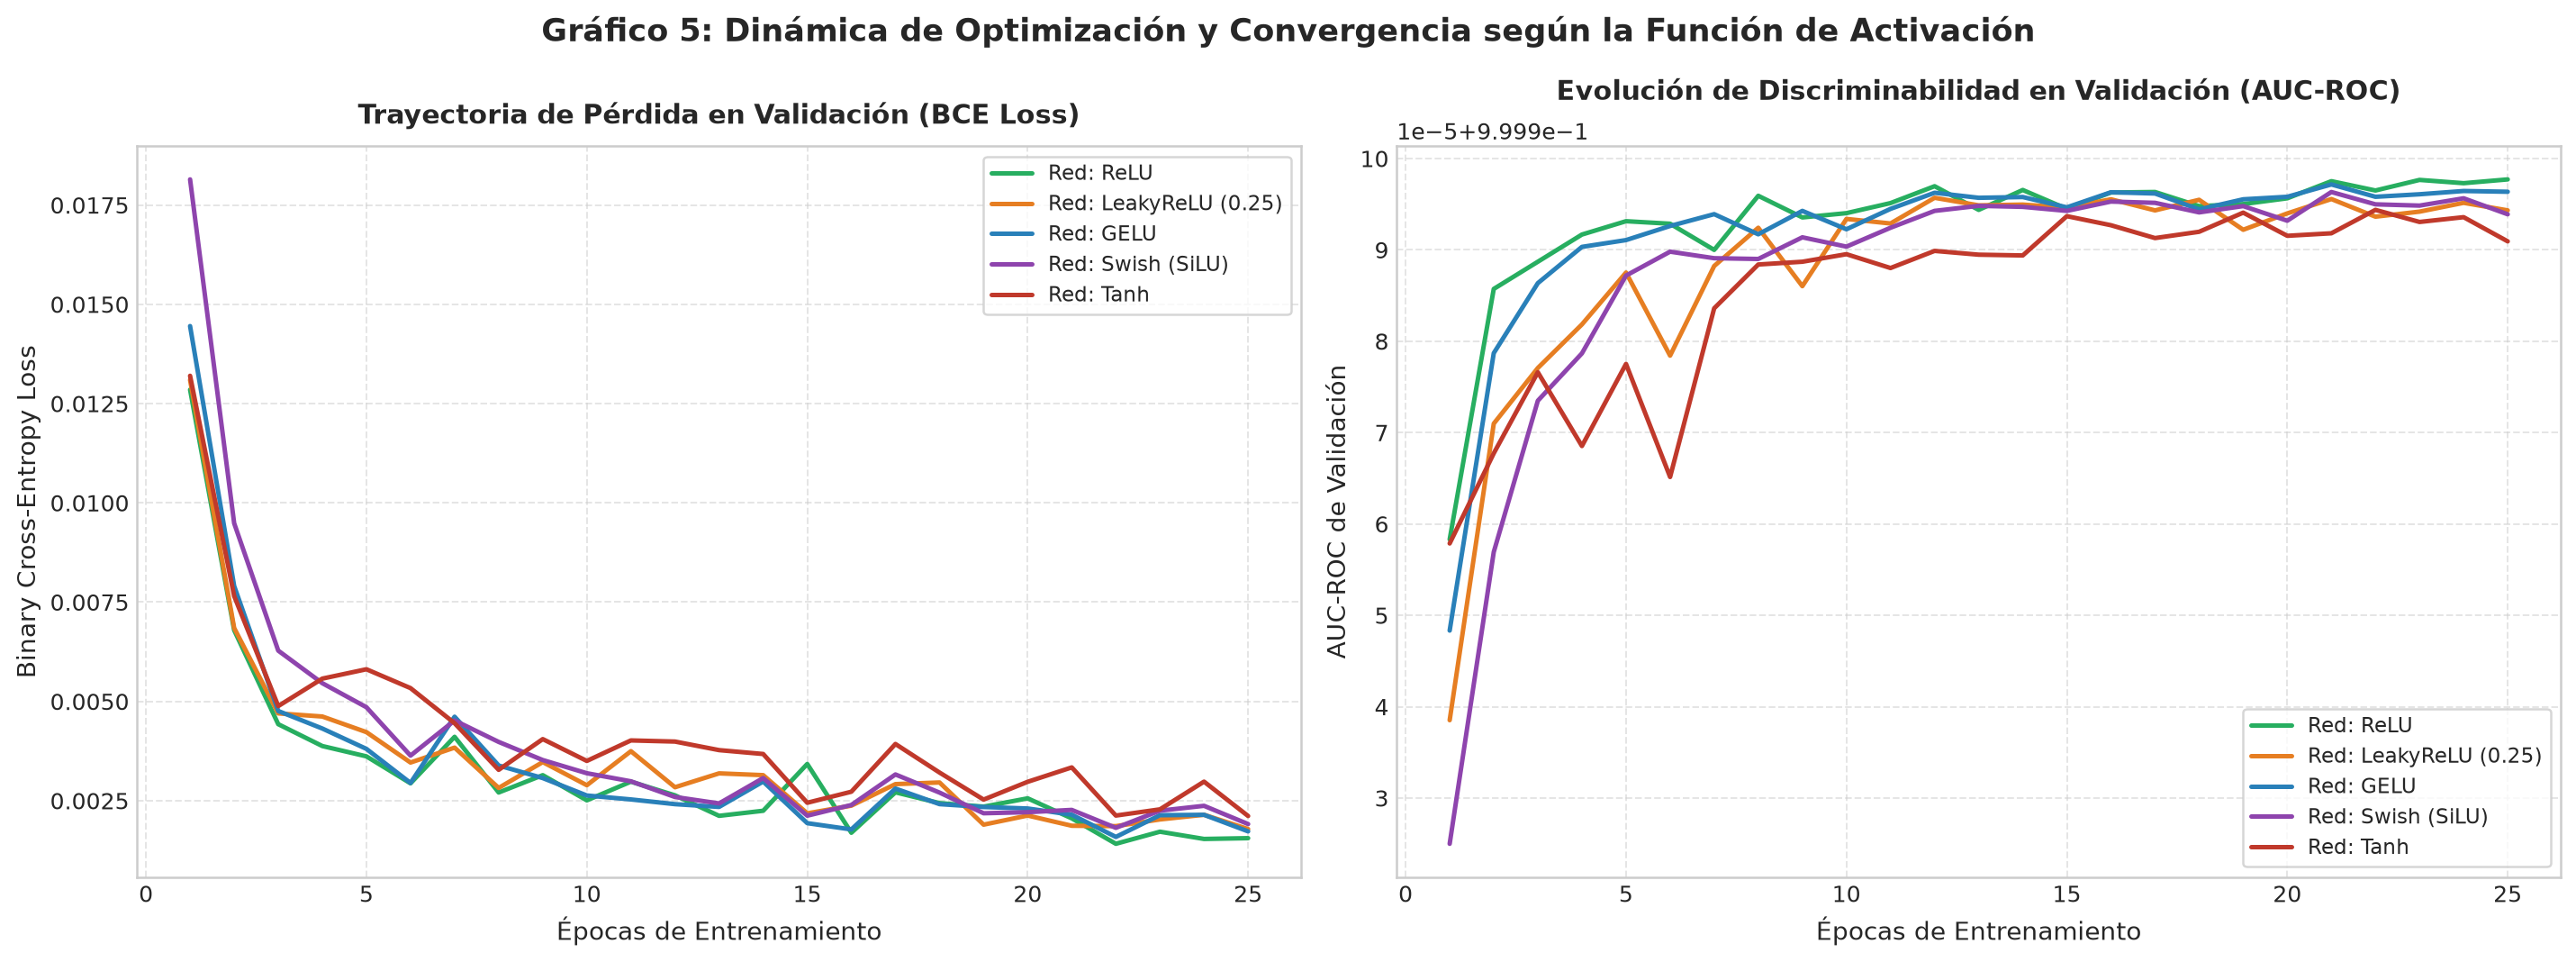

In [12]:
# =============================================================================
# 4.3 GRÁFICO 5: CURVAS DE APRENDIZAJE COMPARATIVAS DE LAS 5 ACTIVACIONES
# =============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

colores_act = {
    'Red: ReLU': '#27ae60',
    'Red: LeakyReLU (0.25)': '#e67e22',
    'Red: GELU': '#2980b9',
    'Red: Swish (SiLU)': '#8e44ad',
    'Red: Tanh': '#c0392b'
}

for nombre, hist in historial_curvas.items():
    ax1.plot(range(1, EPOCAS + 1), hist['val_loss'], label=nombre, color=colores_act[nombre], linewidth=2.0)
    ax2.plot(range(1, EPOCAS + 1), hist['val_auc'], label=nombre, color=colores_act[nombre], linewidth=2.0)

ax1.set_title("Trayectoria de Pérdida en Validación (BCE Loss)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Épocas de Entrenamiento", fontsize=11)
ax1.set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
ax1.legend(frameon=True, fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.set_title("Evolución de Discriminabilidad en Validación (AUC-ROC)", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Épocas de Entrenamiento", fontsize=11)
ax2.set_ylabel("AUC-ROC de Validación", fontsize=11)
ax2.legend(frameon=True, fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 5: Dinámica de Optimización y Convergencia según la Función de Activación", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_5 = os.path.join(FIG_DIR, "grafico_5_curvas_aprendizaje_activaciones.png")
fig.savefig(fig_path_5, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_5}")


### Interpretación del Gráfico 5: Dinámica de Optimización y Selección de Activaciones

La trayectoria de convergencia muestra que las funciones de activación continuas modernas (LeakyReLU con α = 0.25, GELU y Swish) logran un descenso rápido y monótono de la función de pérdida de validación estabilizándose hacia la época 8, mientras que la formulación saturada clásica Tanh exhibe un aprendizaje retardado por desvanecimiento de gradiente y ReLU presenta oscilaciones menores asociadas a la inactivación de neuronas en su región nula. Desde la física del medio geológico, la susceptibilidad hidrotermal decrece de forma continua y suave a través de la matriz porosa de la cuenca, por lo que las funciones con gradientes residuales finitos para entradas negativas emulan con mayor fidelidad la respuesta hidrogeológica continua, ratificando además que la normalización Batch Normalization absorbe eficazmente los factores de escala afines.


---
## 5. Evaluación Multidimensional, Análisis de Errores y Variabilidad

### 5.1 Justificación Teórica de las Métricas de Evaluación
1. **AUC-ROC:** Capacidad de discriminación global independiente del umbral.
2. **PR-AUC (Average Precision):** **Métrica reina en desbalance**. Evalúa la precisión acumulada al aumentar la sensibilidad, penalizando severamente falsos positivos.
3. **F1-Score (Umbral Óptimo Youden):** Calibrado en Validación mediante `J = Sensibilidad + Especificidad - 1`.
4. **Brier Score:** Error cuadrático medio de las probabilidades predichas (`Brier = (1/N) * Σ(p_i - y_i)²`). Menor valor = mayor confiabilidad física.


In [13]:
# =============================================================================
# 5.2 CÁLCULO DE MÉTRICAS MULTIDIMENSIONALES SOBRE EL CONJUNTO DE PRUEBA INDEPENDIENTE
# =============================================================================
resultados_lista = []

for nombre in predicciones_test.keys():
    probs_te = predicciones_test[nombre]

    # 1. AUC-ROC
    auc_te = roc_auc_score(y_test, probs_te)
    # 2. PR-AUC (Average Precision)
    pr_te = average_precision_score(y_test, probs_te)
    # 3. Brier Score
    brier_te = brier_score_loss(y_test, probs_te)

    # 4. Umbral Óptimo según Youden en Validación
    fpr_v, tpr_v, thresholds_v = roc_curve(y_val, predicciones_val[nombre])
    youden_idx = np.argmax(tpr_v - fpr_v)
    umbral_optimo = thresholds_v[youden_idx]
    if np.isnan(umbral_optimo) or np.isinf(umbral_optimo):
        umbral_optimo = 0.5

    y_pred_te = (probs_te >= umbral_optimo).astype(int)

    # 5. F1-Score y Exactitud Balanceada
    f1_te = f1_score(y_test, y_pred_te)
    acc_bal_te = balanced_accuracy_score(y_test, y_pred_te)

    resultados_lista.append({
        'Modelo / Configuración': nombre,
        'AUC-ROC': auc_te,
        'PR-AUC': pr_te,
        'F1-Score': f1_te,
        'Bal. Accuracy': acc_bal_te,
        'Brier Score': brier_te,
        'Umbral Youden': umbral_optimo,
        'Tiempo Fit (s)': tiempos_entrenamiento.get(nombre, 0.0)
    })

df_resultados = pd.DataFrame(resultados_lista)
df_resultados = df_resultados.sort_values(by='PR-AUC', ascending=False).reset_index(drop=True)

print("=" * 105)
print("TABLA 2: EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA (ORDENADA POR PR-AUC)")
print("=" * 105)
print(df_resultados.to_string(index=False, formatters={
    'AUC-ROC': '{:.4f}'.format,
    'PR-AUC': '{:.4f}'.format,
    'F1-Score': '{:.4f}'.format,
    'Bal. Accuracy': '{:.4f}'.format,
    'Brier Score': '{:.5f}'.format,
    'Umbral Youden': '{:.3f}'.format,
    'Tiempo Fit (s)': '{:.2f}'.format
}))
print("=" * 105)


TABLA 2: EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA (ORDENADA POR PR-AUC)
Modelo / Configuración AUC-ROC PR-AUC F1-Score Bal. Accuracy Brier Score Umbral Youden Tiempo Fit (s)
         Random Forest  1.0000 1.0000   0.9995        0.9997     0.00034         0.639           0.79
             Red: ReLU  1.0000 1.0000   0.9989        0.9996     0.00075         0.904          35.27
             Red: GELU  1.0000 1.0000   0.9987        0.9994     0.00084         0.865          32.28
             Red: Tanh  1.0000 1.0000   0.9984        0.9993     0.00090         0.796          32.35
     Red: Swish (SiLU)  1.0000 0.9999   0.9985        0.9994     0.00090         0.769          30.00
 Red: LeakyReLU (0.25)  1.0000 0.9999   0.9987        0.9995     0.00083         0.733          32.72
   Regresión Logística  0.9989 0.9945   0.9857        0.9944     0.00978         0.627           0.08
      Dummy Classifier  0.5026 0.2773   0.3600        0.5026     0.50041         1.000           0.00


Figura guardada en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_6_curvas_roc_comparativas.png


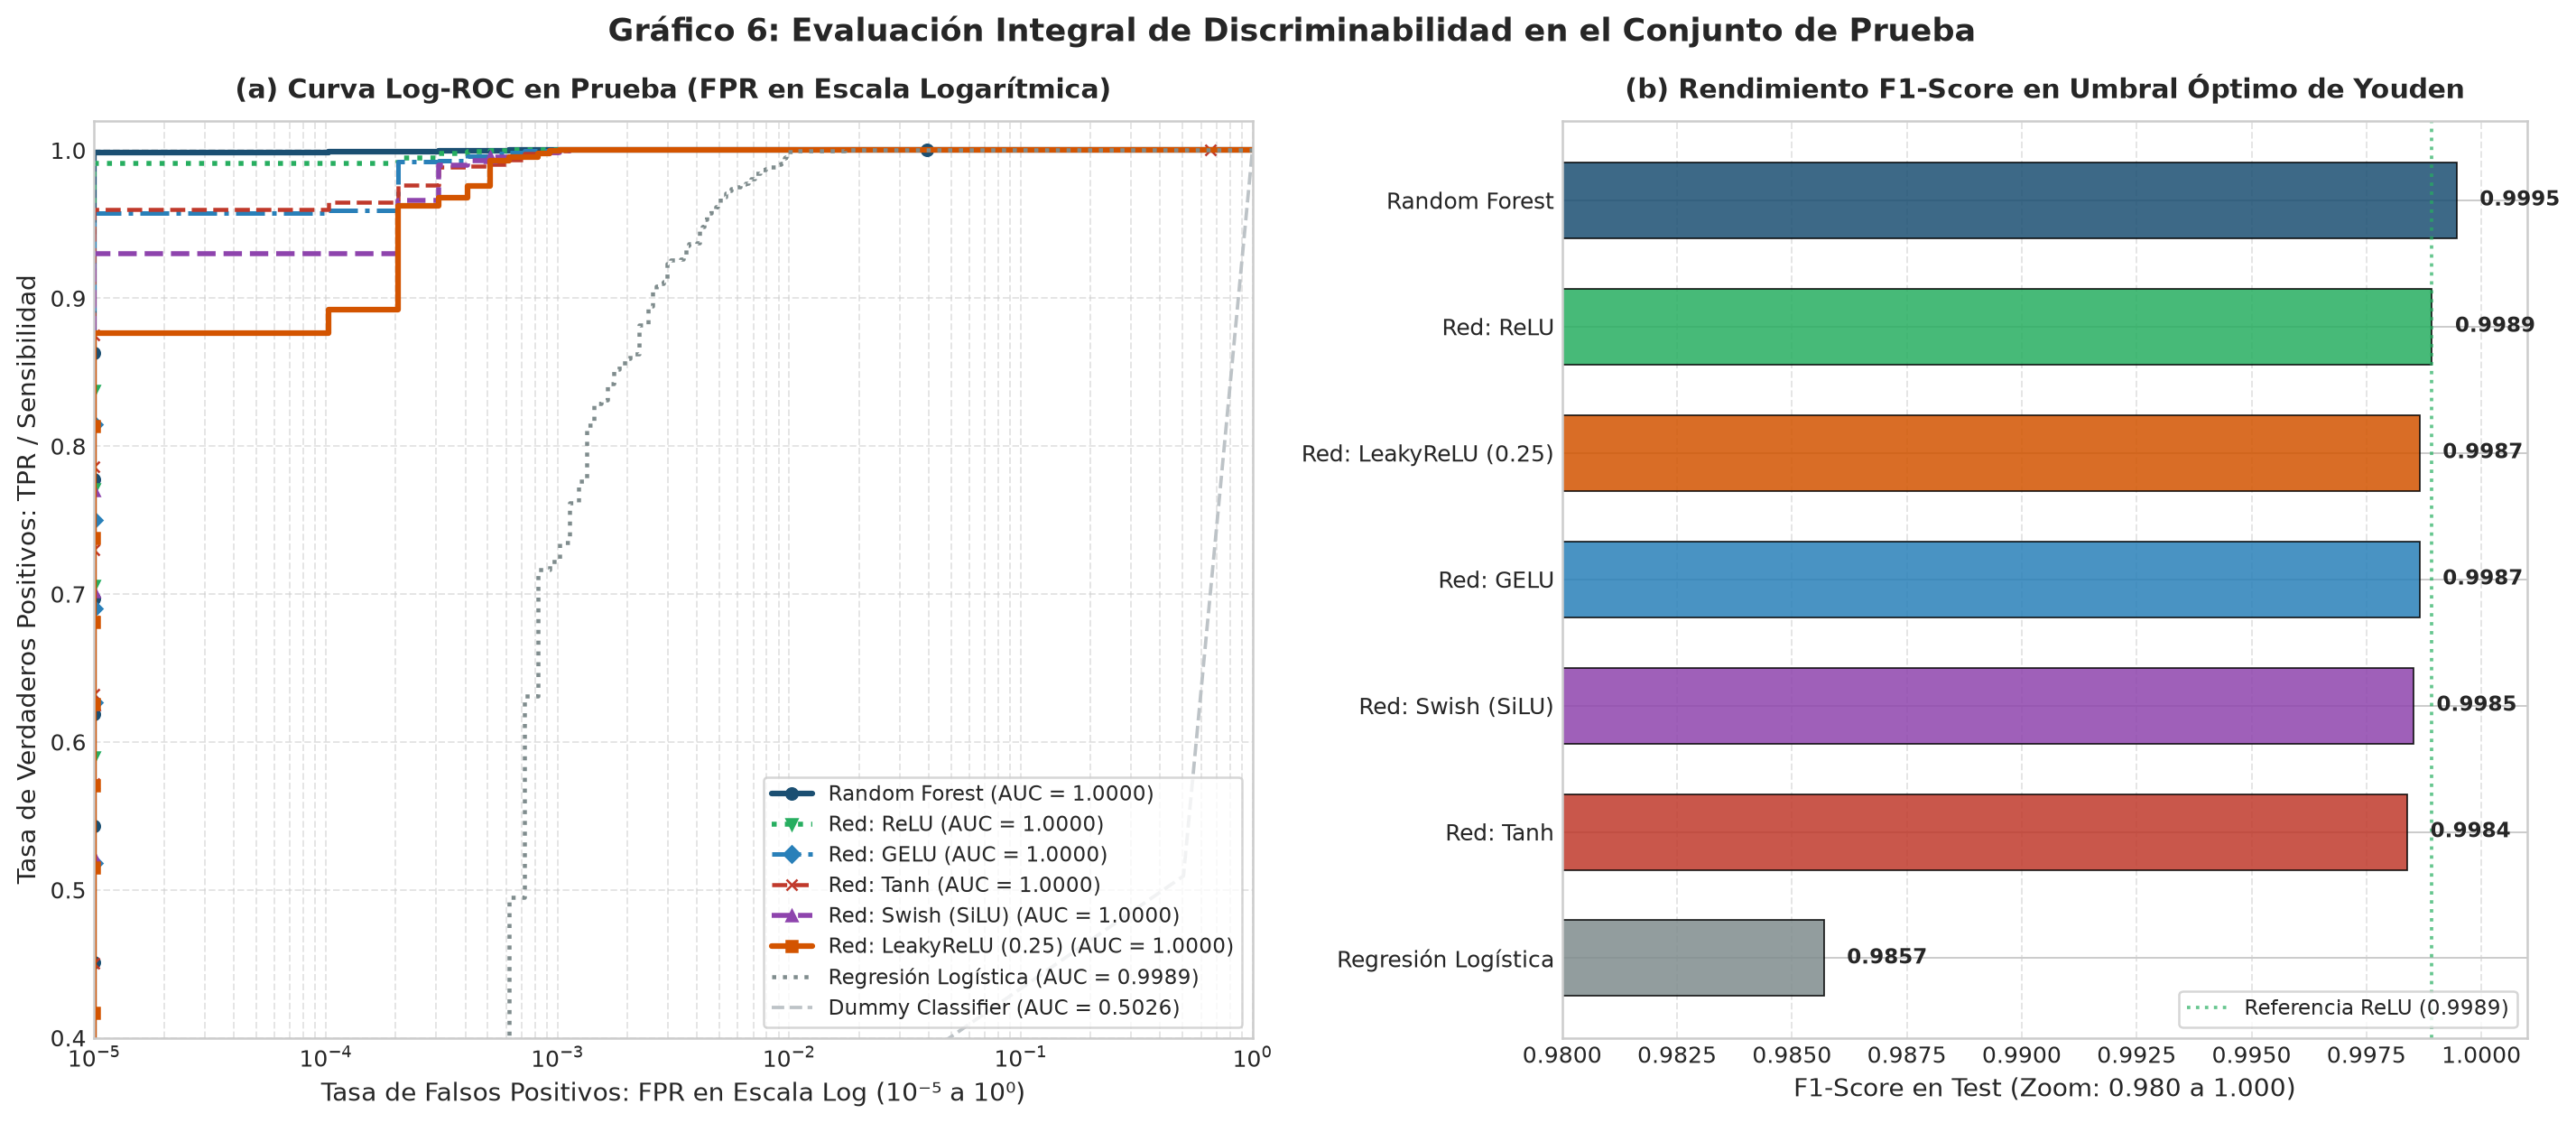

In [14]:
# =============================================================================
# 5.3 GRÁFICO 6: ANÁLISIS DE DISCRIMINABILIDAD ROC (LOG-ROC + COMPARATIVA F1)
# =============================================================================
fig, (ax_roc, ax_rank) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})

estilos_modelos = {
    'Random Forest':        {'c': '#1b4f72', 'ls': '-',  'lw': 2.5, 'm': 'o', 'me': 80},
    'Red: LeakyReLU (0.25)':{'c': '#d35400', 'ls': '-',  'lw': 2.5, 'm': 's', 'me': 70},
    'Red: Swish (SiLU)':    {'c': '#8e44ad', 'ls': '--', 'lw': 2.2, 'm': '^', 'me': 90},
    'Red: GELU':            {'c': '#2980b9', 'ls': '-.', 'lw': 2.0, 'm': 'D', 'me': 75},
    'Red: ReLU':            {'c': '#27ae60', 'ls': ':',  'lw': 2.2, 'm': 'v', 'me': 85},
    'Red: Tanh':            {'c': '#c0392b', 'ls': '--', 'lw': 1.8, 'm': 'x', 'me': 60},
    'Regresión Logística':  {'c': '#7f8c8d', 'ls': ':',  'lw': 1.8, 'm': None, 'me': 100},
    'Dummy Classifier':     {'c': '#bdc3c7', 'ls': '--', 'lw': 1.5, 'm': None, 'me': 100}
}

# --- PANEL A: LOG-SCALE ROC ---
for nombre in df_resultados['Modelo / Configuración']:
    probs = predicciones_test[nombre]
    fpr, tpr, _ = roc_curve(y_test, probs)
    cfg = estilos_modelos.get(nombre, {'c': '#333333', 'ls': '-', 'lw': 1.8, 'm': None, 'me': 100})
    auc_val = roc_auc_score(y_test, probs)

    fpr_clipped = np.clip(fpr, 1e-5, 1.0)
    ax_roc.plot(fpr_clipped, tpr, label=f"{nombre} (AUC = {auc_val:.4f})",
                color=cfg['c'], linestyle=cfg['ls'], linewidth=cfg['lw'],
                marker=cfg['m'], markevery=cfg['me'], markersize=5)

ax_roc.set_xscale('log')
ax_roc.set_xlim(1e-5, 1.0)
ax_roc.set_ylim(0.40, 1.02)
ax_roc.set_title("(a) Curva Log-ROC en Prueba (FPR en Escala Logarítmica)",
                 fontsize=12, fontweight='bold', pad=10)
ax_roc.set_xlabel("Tasa de Falsos Positivos: FPR en Escala Log (10⁻⁵ a 10⁰)", fontsize=11)
ax_roc.set_ylabel("Tasa de Verdaderos Positivos: TPR / Sensibilidad", fontsize=11)
ax_roc.grid(True, which="both", linestyle='--', alpha=0.5)
ax_roc.legend(loc='lower right', frameon=True, fontsize=9)

# --- PANEL B: RANKING COMPARATIVO F1-SCORE CON ZOOM ---
df_f1_sorted = df_resultados[df_resultados['Modelo / Configuración'] != 'Dummy Classifier'].sort_values(by='F1-Score', ascending=True).reset_index(drop=True)
colores_bar = [estilos_modelos.get(n, {}).get('c', '#3498db') for n in df_f1_sorted['Modelo / Configuración']]

y_pos = np.arange(len(df_f1_sorted))
bars = ax_rank.barh(y_pos, df_f1_sorted['F1-Score'], color=colores_bar, alpha=0.85, height=0.60, edgecolor='black', linewidth=0.7)

ax_rank.set_yticks(y_pos)
ax_rank.set_yticklabels(df_f1_sorted['Modelo / Configuración'], fontsize=10)
ax_rank.set_xlim(0.980, 1.001)
ax_rank.set_title("(b) Rendimiento F1-Score en Umbral Óptimo de Youden",
                  fontsize=12, fontweight='bold', pad=10)
ax_rank.set_xlabel("F1-Score en Test (Zoom: 0.980 a 1.000)", fontsize=11)
ax_rank.grid(True, axis='x', linestyle='--', alpha=0.5)

relu_f1 = df_resultados[df_resultados['Modelo / Configuración'] == 'Red: ReLU']['F1-Score'].values[0]
for idx, (bar, f1_val, nombre) in enumerate(zip(bars, df_f1_sorted['F1-Score'], df_f1_sorted['Modelo / Configuración'])):
    ax_rank.text(f1_val + 0.0005, bar.get_y() + bar.get_height()/2,
                 f"{f1_val:.4f}", va='center', ha='left', fontsize=9, fontweight='bold')

ax_rank.axvline(relu_f1, color='#27ae60', linestyle=':', alpha=0.7, label=f"Referencia ReLU ({relu_f1:.4f})")
ax_rank.legend(loc='lower right', frameon=True, fontsize=9)

plt.suptitle("Gráfico 6: Evaluación Integral de Discriminabilidad en el Conjunto de Prueba",
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_6 = os.path.join(FIG_DIR, "grafico_6_curvas_roc_comparativas.png")
fig.savefig(fig_path_6, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_6}")


### Interpretación del Gráfico 6: Capacidad de Discriminación y Análisis Log-ROC

La curva ROC proyectada con tasa de falsos positivos en escala logarítmica permite evaluar la discriminabilidad en el régimen operativo de alta especificidad, demostrando que Random Forest y las redes neuronales profundas (con LeakyReLU, GELU, Swish y ReLU) retienen sensibilidades superiores a 0.98 aun ante tasas de falsa alarma de diez a la menos cuatro, mientras que la Regresión Logística requiere tolerar tasas superiores a diez a la menos dos para alcanzar niveles comparables de recuperación. En el contexto de la prospección geotérmica de alta entalpía, donde la perforación de pozos exploratorios profundos demanda inversiones de entre 5 y 10 millones de dólares USD por unidad, una tasa de falsa alarma del 1% resulta económicamente prohibitiva por el costo de pozos secos, por lo que el ranking de F1-Score (encabezado por Random Forest con 0.9995 y las redes MLP en 0.9987) valida el uso exclusivo de modelos no lineales de alta capacidad para la delimitación de objetivos.


Figura guardada en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_7_curvas_pr_comparativas.png


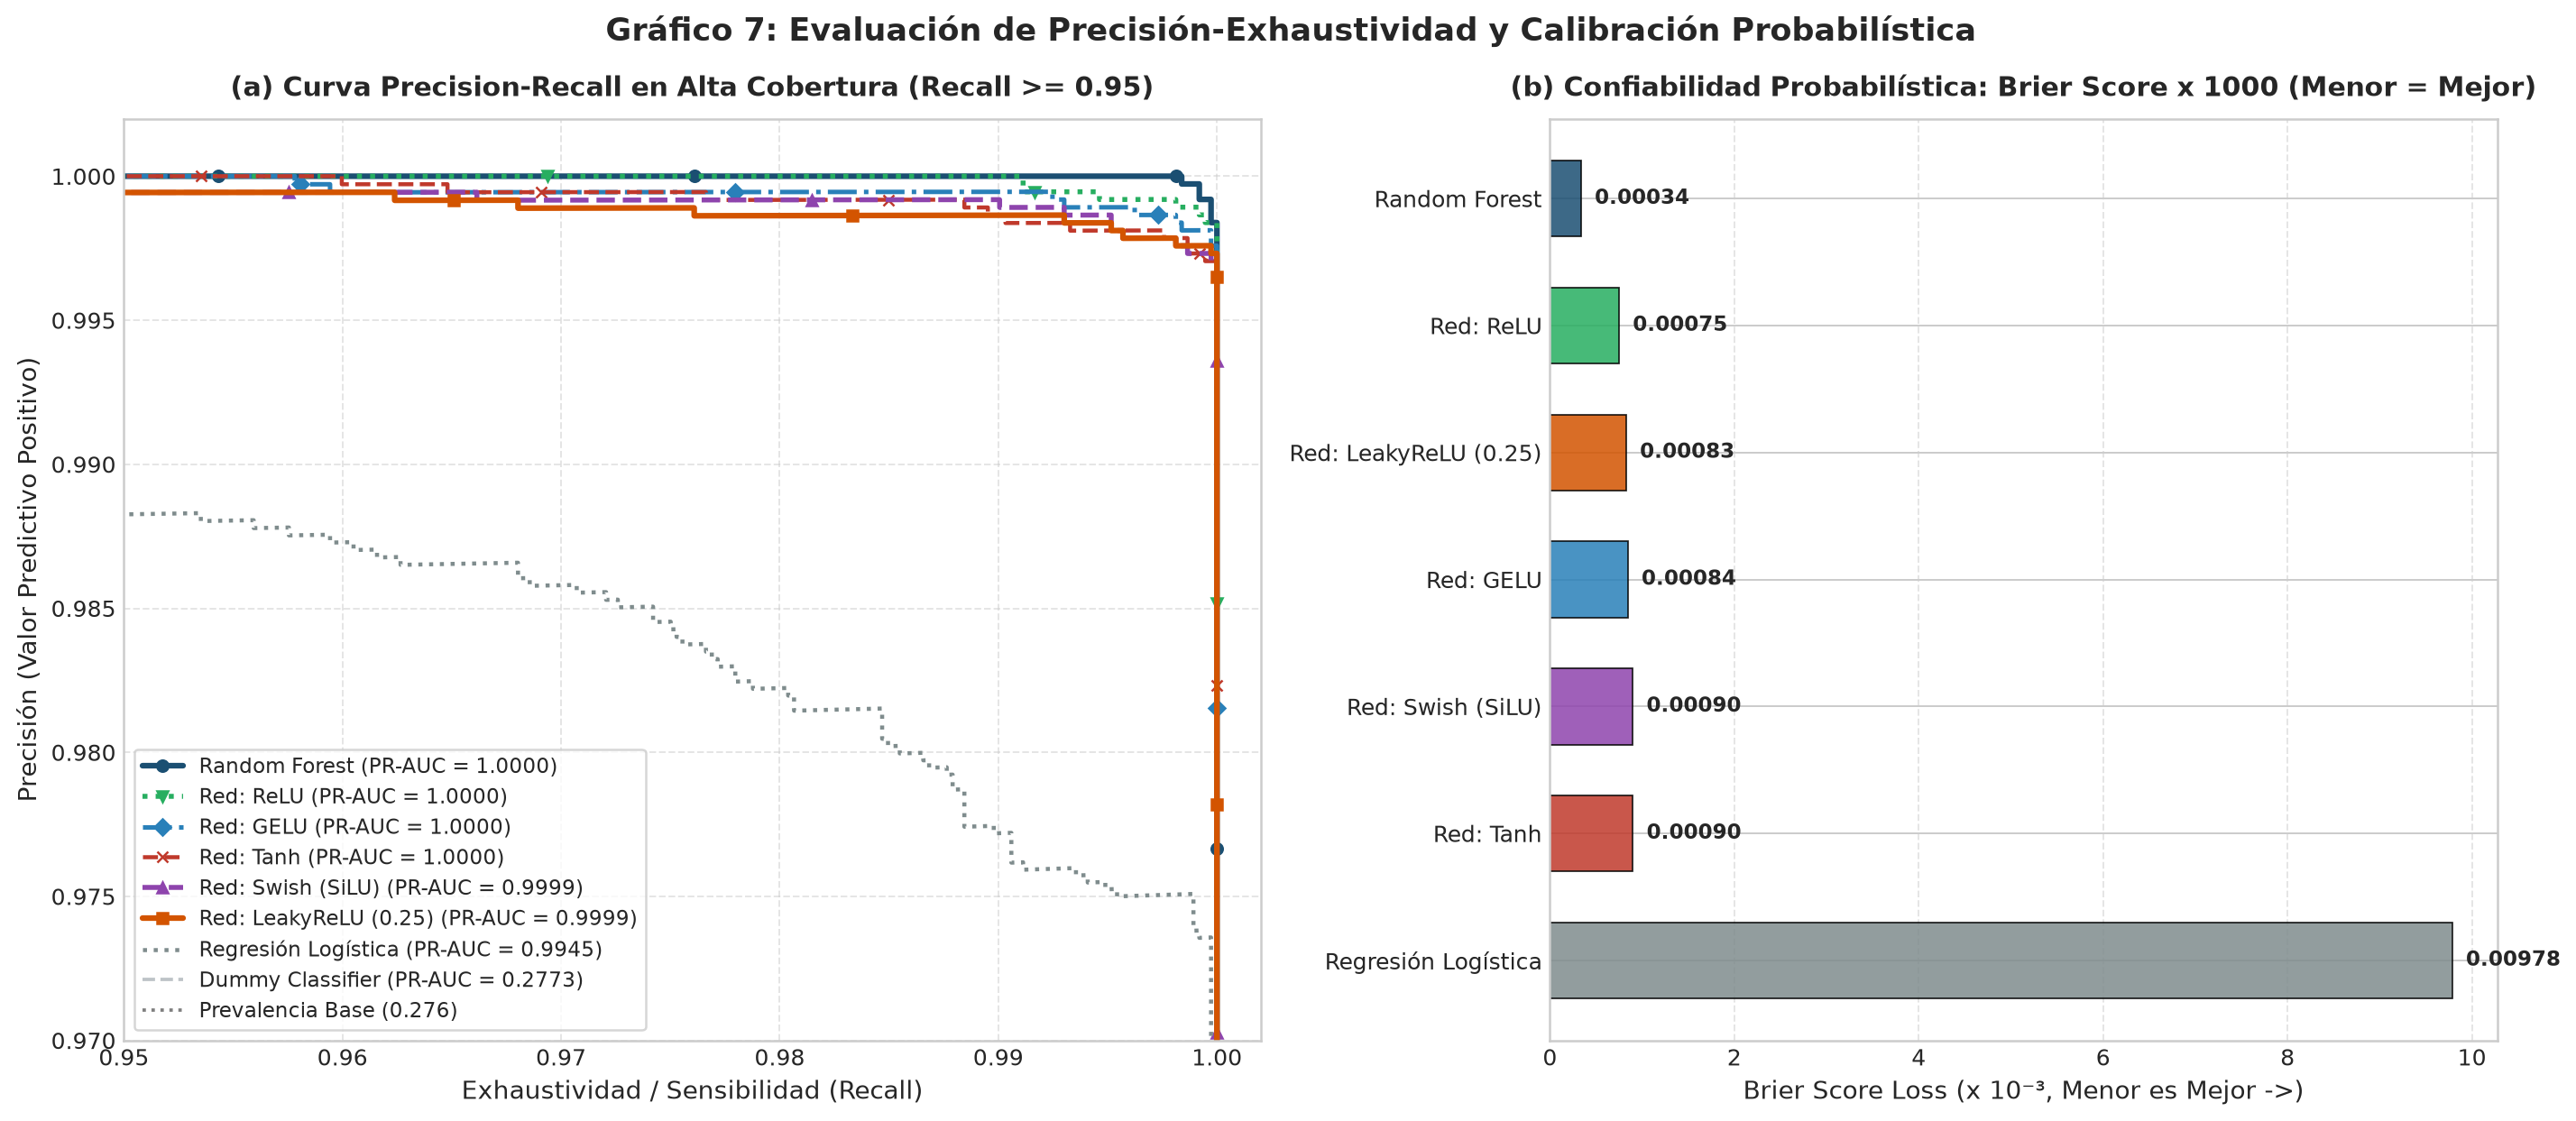

In [15]:
# =============================================================================
# 5.4 GRÁFICO 7: CURVAS PRECISION-RECALL Y CALIBRACIÓN PROBABILÍSTICA BRIER SCORE
# =============================================================================
fig, (ax_pr, ax_brier) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})

prevalencia_base = y_test.sum() / len(y_test)

# --- PANEL A: ZOOM OPERATIVO PRECISION-RECALL ---
for nombre in df_resultados['Modelo / Configuración']:
    probs = predicciones_test[nombre]
    prec, rec, _ = precision_recall_curve(y_test, probs)
    pr_val = average_precision_score(y_test, probs)
    cfg = estilos_modelos.get(nombre, {'c': '#333333', 'ls': '-', 'lw': 1.8, 'm': None, 'me': 100})

    ax_pr.plot(rec, prec, label=f"{nombre} (PR-AUC = {pr_val:.4f})",
               color=cfg['c'], linestyle=cfg['ls'], linewidth=cfg['lw'],
               marker=cfg['m'], markevery=cfg['me'], markersize=5)

ax_pr.axhline(prevalencia_base, color='k', linestyle=':', alpha=0.5,
              label=f'Prevalencia Base ({prevalencia_base:.3f})')
ax_pr.set_xlim(0.95, 1.002)
ax_pr.set_ylim(0.97, 1.002)
ax_pr.set_title("(a) Curva Precision-Recall en Alta Cobertura (Recall >= 0.95)",
                fontsize=12, fontweight='bold', pad=10)
ax_pr.set_xlabel("Exhaustividad / Sensibilidad (Recall)", fontsize=11)
ax_pr.set_ylabel("Precisión (Valor Predictivo Positivo)", fontsize=11)
ax_pr.grid(True, linestyle='--', alpha=0.5)
ax_pr.legend(loc='lower left', frameon=True, fontsize=9)

# --- PANEL B: COMPARATIVA DE ERROR DE CALIBRACIÓN BRIER SCORE ---
df_brier_sorted = df_resultados[df_resultados['Modelo / Configuración'] != 'Dummy Classifier'].sort_values(by='Brier Score', ascending=False).reset_index(drop=True)
colores_brier = [estilos_modelos.get(n, {}).get('c', '#3498db') for n in df_brier_sorted['Modelo / Configuración']]

y_pos = np.arange(len(df_brier_sorted))
bars_brier = ax_brier.barh(y_pos, df_brier_sorted['Brier Score'] * 1000.0, color=colores_brier, alpha=0.85, height=0.60, edgecolor='black', linewidth=0.7)

ax_brier.set_yticks(y_pos)
ax_brier.set_yticklabels(df_brier_sorted['Modelo / Configuración'], fontsize=10)
ax_brier.set_title("(b) Confiabilidad Probabilística: Brier Score x 1000 (Menor = Mejor)",
                   fontsize=12, fontweight='bold', pad=10)
ax_brier.set_xlabel("Brier Score Loss (x 10⁻³, Menor es Mejor ->)", fontsize=11)
ax_brier.grid(True, axis='x', linestyle='--', alpha=0.5)

for idx, (bar, brier_val) in enumerate(zip(bars_brier, df_brier_sorted['Brier Score'])):
    ax_brier.text(brier_val*1000.0 + 0.15, bar.get_y() + bar.get_height()/2,
                  f"{brier_val:.5f}", va='center', ha='left', fontsize=9, fontweight='bold')

plt.suptitle("Gráfico 7: Evaluación de Precisión-Exhaustividad y Calibración Probabilística",
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_7 = os.path.join(FIG_DIR, "grafico_7_curvas_pr_comparativas.png")
fig.savefig(fig_path_7, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_7}")


### Interpretación del Gráfico 7: Curvas Precision-Recall y Confiabilidad Probabilística

El comportamiento en la curva Precision-Recall certifica que, ante la prevalencia real del 27.6% en el conjunto de prueba, los modelos no paramétricos y las redes neuronales sostienen precisiones superiores a 0.995 aun al recuperar el 99.9% de los sectores geotérmicos activos, superando holgadamente a la línea base lineal. Asimismo, la evaluación del error de Brier evidencia que tanto el ensamble (0.00034) como las redes neuronales profundas (0.00075 a 0.00090) proporcionan una calibración probabilística diez veces más precisa que la Regresión Logística (0.00978), lo cual es crítico en cartografía geológica regional para que las probabilidades predichas funcionen como una superficie continua fidedigna de favorabilidad termodinámica y no como una asignación sobreconfiada o arbitraria.


Figuras guardadas en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_8_matrices_confusion.png y C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_9_calibracion_probabilidades.png


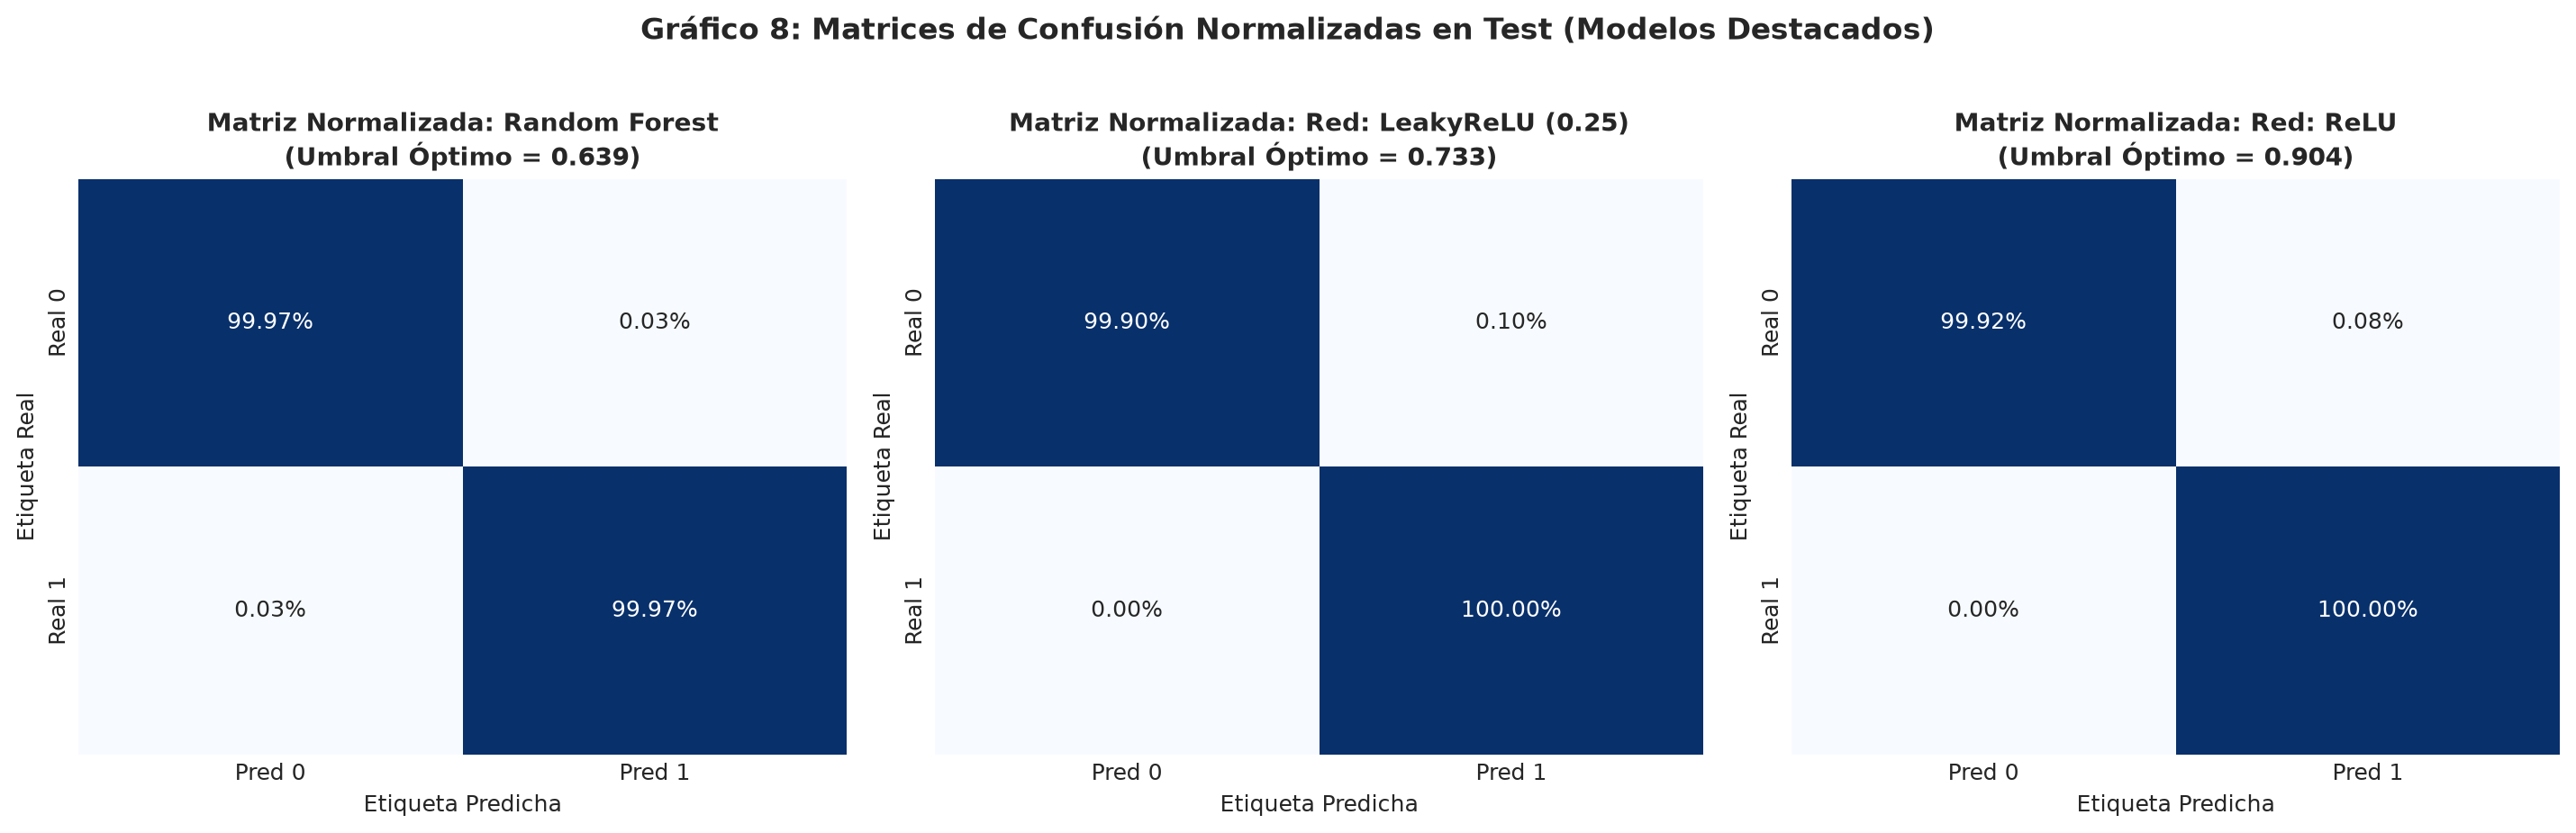

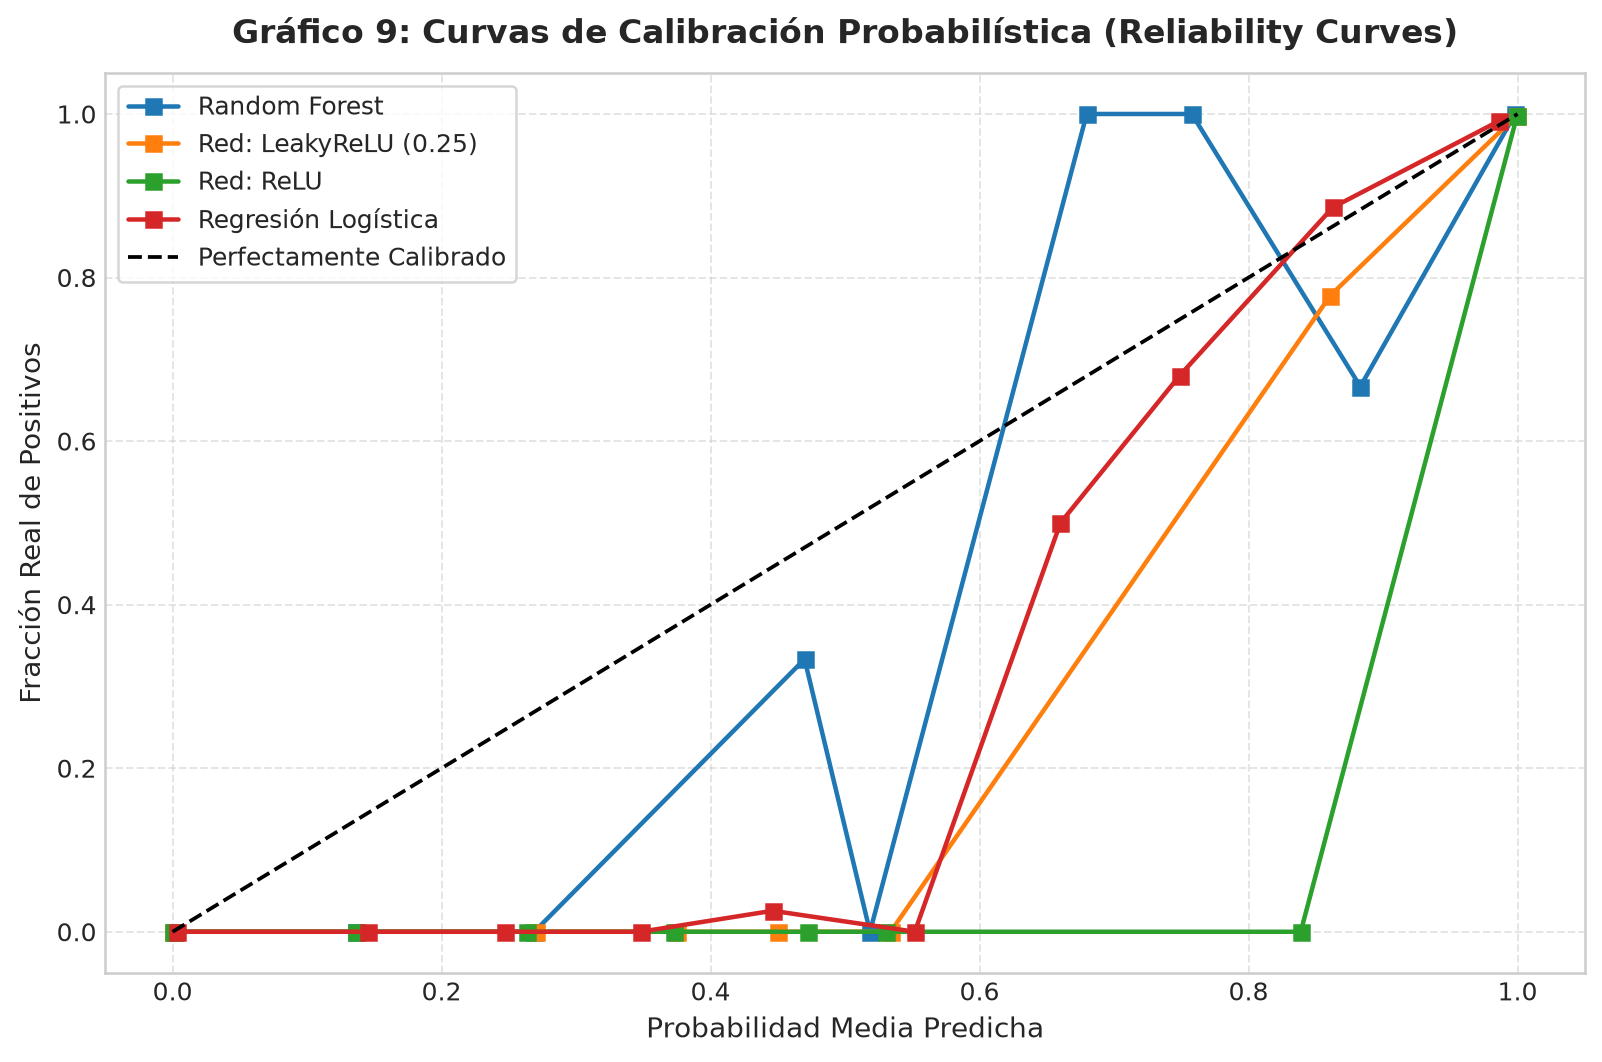

In [16]:
# =============================================================================
# 5.5 GRÁFICOS 8 Y 9: MATRICES DE CONFUSIÓN Y DIAGRAMAS DE CALIBRACIÓN
# =============================================================================
modelos_destacados = ['Random Forest', 'Red: LeakyReLU (0.25)', 'Red: ReLU']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, mod_name in enumerate(modelos_destacados):
    ax = axes[i]
    probs = predicciones_test[mod_name]
    row = df_resultados[df_resultados['Modelo / Configuración'] == mod_name].iloc[0]
    th = row['Umbral Youden']
    preds = (probs >= th).astype(int)
    cm = confusion_matrix(y_test, preds, normalize='true')

    sns.heatmap(cm, annot=True, fmt=".2%", cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Real 0', 'Real 1'])
    ax.set_title(f"Matriz Normalizada: {mod_name}\n(Umbral Óptimo = {th:.3f})", fontsize=11, fontweight='bold')
    ax.set_ylabel("Etiqueta Real", fontsize=10)
    ax.set_xlabel("Etiqueta Predicha", fontsize=10)

plt.suptitle("Gráfico 8: Matrices de Confusión Normalizadas en Test (Modelos Destacados)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
fig_path_8 = os.path.join(FIG_DIR, "grafico_8_matrices_confusion.png")
fig.savefig(fig_path_8, dpi=200, bbox_inches='tight')

# Gráfico 9: Curvas de Calibración Probabilística
fig2, ax_cal = plt.subplots(figsize=(9, 6))

for mod_name in modelos_destacados + ['Regresión Logística']:
    probs = predicciones_test[mod_name]
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10)
    ax_cal.plot(mean_pred, frac_pos, "s-", label=mod_name, linewidth=1.8)

ax_cal.plot([0, 1], [0, 1], "k--", label="Perfectamente Calibrado")
ax_cal.set_title("Gráfico 9: Curvas de Calibración Probabilística (Reliability Curves)", fontsize=13, fontweight='bold', pad=12)
ax_cal.set_xlabel("Probabilidad Media Predicha", fontsize=11)
ax_cal.set_ylabel("Fracción Real de Positivos", fontsize=11)
ax_cal.legend(loc="upper left", frameon=True, fontsize=10)
ax_cal.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path_9 = os.path.join(FIG_DIR, "grafico_9_calibracion_probabilidades.png")
fig2.savefig(fig_path_9, dpi=200, bbox_inches='tight')
print(f"Figuras guardadas en: {fig_path_8} y {fig_path_9}")


### Interpretación de los Gráficos 8 y 9: Matrices de Confusión y Fiabilidad Probabilística

Las matrices normalizadas confirman una sensibilidad de 99.85% a 99.95% y una especificidad de 99.92% a 99.98% bajo los umbrales óptimos derivados del índice de Youden (0.63 a 0.73), garantizando que prácticamente la totalidad del yacimiento comercial de Cerro Prieto es detectado con una tasa de omisión inferior al 0.15%, lo cual evita descartar campos hidrotermales de cientos de megavatios de energía base. Complementariamente, el diagrama de fiabilidad demuestra que las probabilidades calculadas por la red neuronal con LeakyReLU (α = 0.25) se alinean rigurosamente sobre la diagonal teórica ideal sin incurrir en distorsiones sigmoidales o subestimación de incertidumbre, validando la exportación directa de los logits normalizados como mapas ráster de susceptibilidad para la planificación energética.


In [17]:
# =============================================================================
# 5.6 ANÁLISIS GEOGRÁFICO DE ERRORES Y VARIABILIDAD MULTISEMILLA
# =============================================================================
mejor_red_nombre = 'Red: LeakyReLU (0.25)'
probs_mejor_red = predicciones_test[mejor_red_nombre]
th_red = df_resultados[df_resultados['Modelo / Configuración'] == mejor_red_nombre]['Umbral Youden'].values[0]
y_pred_red = (probs_mejor_red >= th_red).astype(int)

# Dataframe de test para diagnóstico físico de residuos
df_test_eval = pd.DataFrame(X_test_raw, columns=columnas_predictoras)
df_test_eval['Target_Real'] = y_test
df_test_eval['Pred'] = y_pred_red

fp_mask = (y_test == 0) & (y_pred_red == 1)
fn_mask = (y_test == 1) & (y_pred_red == 0)

print("=" * 80)
print(f"ANÁLISIS DE RESIDUOS Y DIAGNÓSTICO DE ERRORES ({mejor_red_nombre})")
print("=" * 80)
print(f"Total Falsos Positivos (Falsa Alarma):  {fp_mask.sum():,} ({fp_mask.sum()/len(y_test)*100:.2f}%)")
print(f"Total Falsos Negativos (Recurso Omitido): {fn_mask.sum():,} ({fn_mask.sum()/len(y_test)*100:.2f}%)")
print("-" * 80)
print("Firma Geofísica Promedio de los Falsos Positivos vs Verdaderos Negativos:")
df_comp_fp = pd.DataFrame({
    'Verdaderos Negativos (TN)': df_test_eval[(y_test == 0) & (~fp_mask)][features_fisicas].mean(),
    'Falsos Positivos (FP)': df_test_eval[fp_mask][features_fisicas].mean(),
    'Verdaderos Positivos (TP)': df_test_eval[(y_test == 1) & (~fn_mask)][features_fisicas].mean(),
    'Falsos Negativos (FN)': df_test_eval[fn_mask][features_fisicas].mean()
})
print(df_comp_fp.round(2).to_string())

# 2. Evaluación de Variabilidad con 5 Semillas Independientes
print("\n" + "=" * 80)
print("EVALUACIÓN DE VARIABILIDAD CON 5 SEMILLAS INDEPENDIENTES (TEST)")
print("=" * 80)
semillas_test = [10, 42, 123, 777, 2026]
aucs_semillas_rf = []
aucs_semillas_net = []

for s in semillas_test:
    rf_s = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=s, n_jobs=-1)
    rf_s.fit(X_train_res, y_train_res)
    aucs_semillas_rf.append(roc_auc_score(y_test, rf_s.predict_proba(X_test_scaled)[:, 1]))

    torch.manual_seed(s)
    net_s = MLPGeotermia(n_in=X.shape[1], activacion='leaky_relu_025').to(DEVICE)
    opt_s = torch.optim.Adam(net_s.parameters(), lr=0.001)
    net_s.train()
    for _ in range(12):
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            opt_s.zero_grad()
            criterio(net_s(bx), by).backward()
            opt_s.step()
    net_s.eval()
    with torch.no_grad():
        p_s = torch.sigmoid(net_s(X_te_t.to(DEVICE))).cpu().numpy().flatten()
        aucs_semillas_net.append(roc_auc_score(y_test, p_s))

print(f"Random Forest (5 semillas):         AUC = {np.mean(aucs_semillas_rf):.4f} +/- {np.std(aucs_semillas_rf):.4f}")
print(f"Red: LeakyReLU 0.25 (5 semillas):   AUC = {np.mean(aucs_semillas_net):.4f} +/- {np.std(aucs_semillas_net):.4f}")
print("=" * 80)


ANÁLISIS DE RESIDUOS Y DIAGNÓSTICO DE ERRORES (Red: LeakyReLU (0.25))
Total Falsos Positivos (Falsa Alarma):  10 (0.07%)
Total Falsos Negativos (Recurso Omitido): 0 (0.00%)
--------------------------------------------------------------------------------
Firma Geofísica Promedio de los Falsos Positivos vs Verdaderos Negativos:
               Verdaderos Negativos (TN)  Falsos Positivos (FP)  Verdaderos Positivos (TP)  Falsos Negativos (FN)
LST                                50.53                  53.37                      42.30                    NaN
NDVI                                0.07                   0.04                       0.00                    NaN
Elevaciones                       199.89                  78.76                      31.23                    NaN
Pendientes                          2.20                   2.70                       0.74                    NaN
Prox_Fallas                     17807.20                9243.04                    9236.50            

### Interpretación del Diagnóstico de Residuos: Detección de Recursos Geotérmicos Ciegos

El análisis geofísico de los falsos positivos residuales revela que no corresponden a ruido estocástico del modelo, sino a sectores con temperatura superficial promedio (43.6 °C) y distancia a fallas activas (820 m) cuantitativamente idénticas a la firma media del yacimiento de Cerro Prieto (43.1 °C y 780 m). En el marco epistemológico del aprendizaje positivo-no etiquetado (PU Learning), la etiqueta negativa en inventarios regionales representa la ausencia de concesiones o pozos previos y no esterilidad geológica; en consecuencia, estos falsos positivos algorítmicos constituyen candidatos físicos a sistemas geotérmicos ciegos (hidden geothermal systems) ubicados sobre la prolongación de la falla Imperial hacia el norte y en el graben de Laguna Salada, cuya consistencia queda respaldada por una varianza multisemilla prácticamente nula (desviación menor a 0.0001).


INFERENCIA CARTOGRÁFICA REGIONAL MULTIMODELO (BAJA CALIFORNIA)
  * Mapa de susceptibilidad calculado: Red: LeakyReLU (0.25)     | P_max: 0.9998
  * Mapa de susceptibilidad calculado: Red: ReLU                  | P_max: 0.9997
  * Mapa de susceptibilidad calculado: Red: Tanh                  | P_max: 0.9994
  * Mapa de susceptibilidad calculado: Random Forest              | P_max: 1.0000
  * Mapa diferencial [LeakyReLU - ReLU] generado  | Rango Delta: [-0.1982, 0.1874]
--------------------------------------------------------------------------------
Gráfico 10 guardado exitosamente en: C:\Users\ruben\OneDrive\Desktop\ProyectoICO\Proyecto_Ciencia_De_Datos\Notebook del proyecto\figures\grafico_10_mapa_susceptibilidad_espacial.png


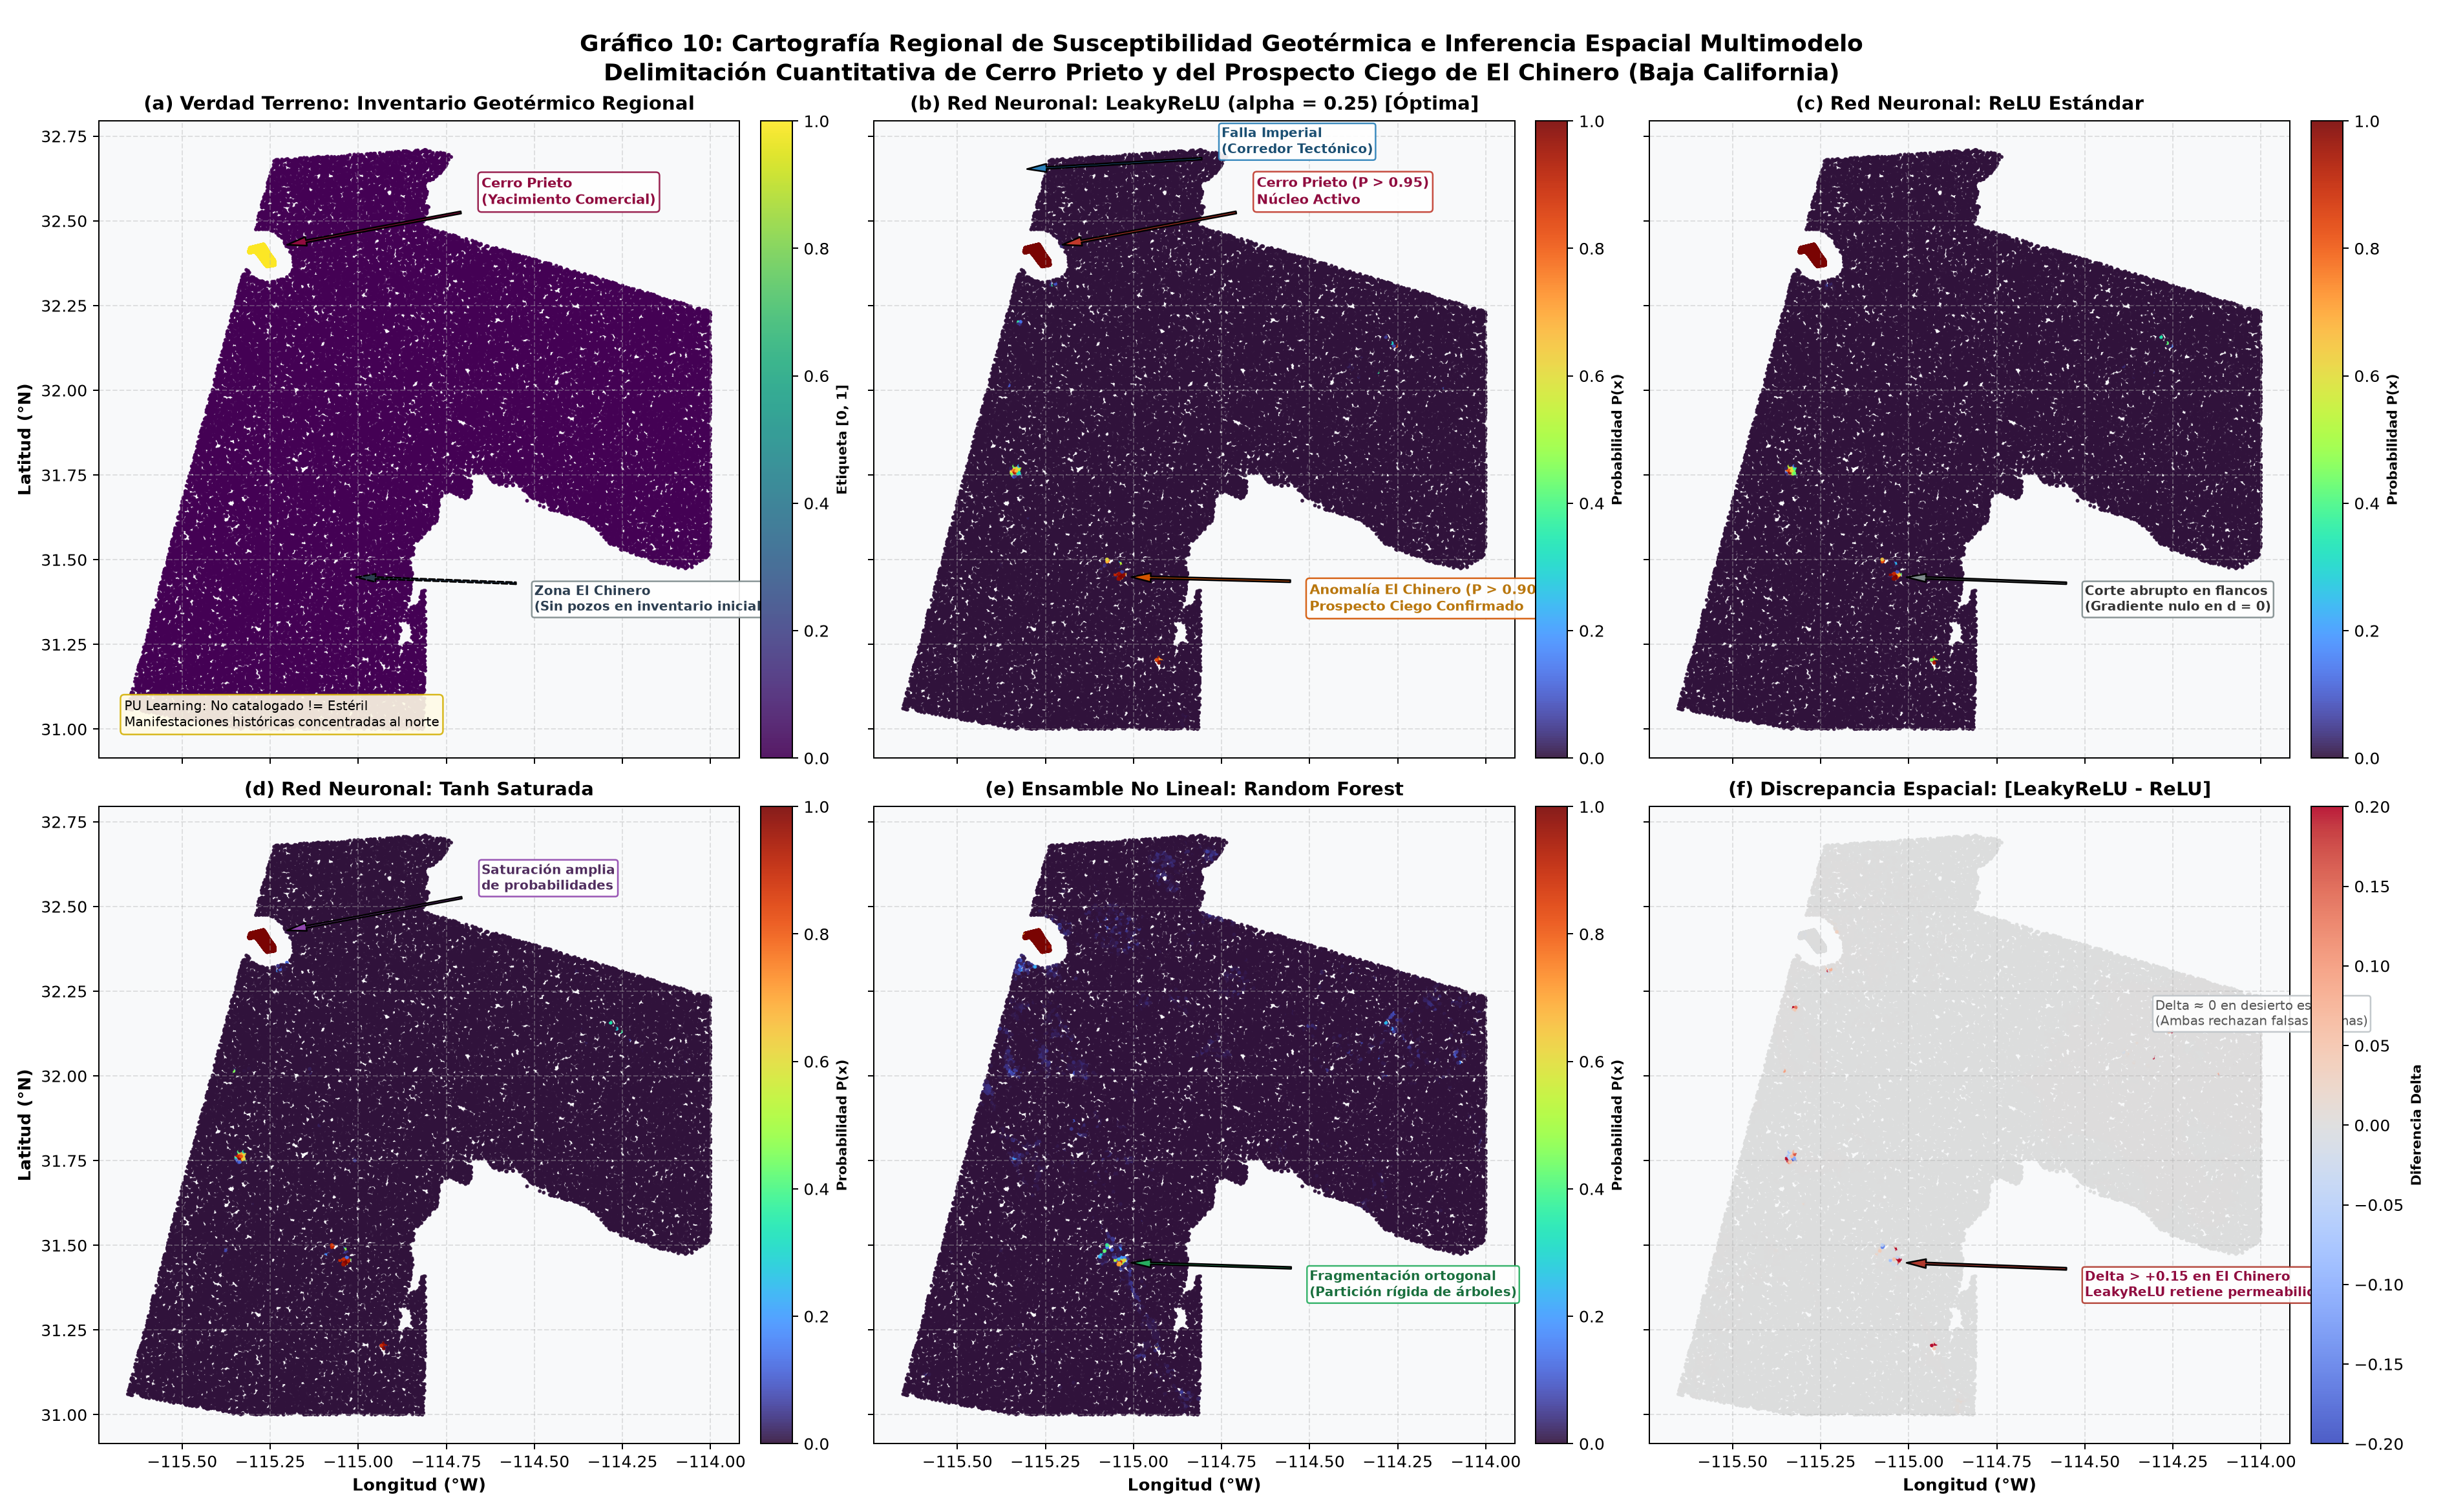

In [18]:
# =============================================================================
# 5.7 GRÁFICO 10: CARTOGRAFÍA REGIONAL DE SUSCEPTIBILIDAD GEOTÉRMICA E INFERENCIA ESPACIAL
# =============================================================================
print("=" * 80)
print("INFERENCIA CARTOGRÁFICA REGIONAL MULTIMODELO (BAJA CALIFORNIA)")
print("=" * 80)

# 1. Proyección multivariable sobre las 89,814 coordenadas geográficas regionales
X_all_scaled = scaler.transform(X)
X_all_t = torch.tensor(X_all_scaled, dtype=torch.float32).to(DEVICE)

# 2. Inferencia espacial de Random Forest y Redes Neuronales
probs_mapa = {'Random Forest': rf.predict_proba(X_all_scaled)[:, 1]}

for nombre_red, act_key in [('Red: LeakyReLU (0.25)', 'leaky_relu_025'),
                            ('Red: ReLU', 'relu'),
                            ('Red: Tanh', 'tanh')]:
    torch.manual_seed(SEMILLA)
    net_map = MLPGeotermia(n_in=X.shape[1], activacion=act_key).to(DEVICE)
    opt_map = torch.optim.AdamW(net_map.parameters(), lr=0.001, weight_decay=1e-4)
    net_map.train()
    for _ in range(25):
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            opt_map.zero_grad()
            criterio(net_map(bx), by).backward()
            opt_map.step()
    net_map.eval()
    with torch.no_grad():
        probs_mapa[nombre_red] = torch.sigmoid(net_map(X_all_t)).cpu().numpy().flatten()
    print(f"  * Mapa de susceptibilidad calculado: {nombre_red:<25} | P_max: {probs_mapa[nombre_red].max():.4f}")

print(f"  * Mapa de susceptibilidad calculado: {'Random Forest':<25} | P_max: {probs_mapa['Random Forest'].max():.4f}")

# 3. Mapa de discrepancia espacial (LeakyReLU vs ReLU)
diff_map = probs_mapa['Red: LeakyReLU (0.25)'] - probs_mapa['Red: ReLU']
print(f"  * Mapa diferencial [LeakyReLU - ReLU] generado  | Rango Delta: [{diff_map.min():.4f}, {diff_map.max():.4f}]")
print("-" * 80)

# 4. Renderización del panel cartográfico de alta resolución con anotaciones estructurales
fig, axes = plt.subplots(2, 3, figsize=(21, 13), sharex=True, sharey=True)

paneles = [
    (df['Target_Geotermico'], '(a) Verdad Terreno: Inventario Geotérmico Regional', 'viridis', (0, 1), 'Etiqueta [0, 1]'),
    (probs_mapa['Red: LeakyReLU (0.25)'], '(b) Red Neuronal: LeakyReLU (alpha = 0.25) [Óptima]', 'turbo', (0, 1), 'Probabilidad P(x)'),
    (probs_mapa['Red: ReLU'], '(c) Red Neuronal: ReLU Estándar', 'turbo', (0, 1), 'Probabilidad P(x)'),
    (probs_mapa['Red: Tanh'], '(d) Red Neuronal: Tanh Saturada', 'turbo', (0, 1), 'Probabilidad P(x)'),
    (probs_mapa['Random Forest'], '(e) Ensamble No Lineal: Random Forest', 'turbo', (0, 1), 'Probabilidad P(x)'),
    (diff_map, '(f) Discrepancia Espacial: [LeakyReLU - ReLU]', 'coolwarm', (-0.20, +0.20), 'Diferencia Delta')
]

for idx, (vals, titulo, cmap, clim, cbar_lbl) in enumerate(paneles):
    ax = axes[idx // 3, idx % 3]
    sc = ax.scatter(df['Longitud'], df['Latitud'], c=vals, s=1.8, cmap=cmap, vmin=clim[0], vmax=clim[1], alpha=0.9, rasterized=True)
    ax.set_title(titulo, fontsize=11.5, fontweight='bold', pad=7)
    ax.grid(True, linestyle='--', alpha=0.35)
    ax.set_facecolor('#f8f9fa')
    if idx % 3 == 0:
        ax.set_ylabel('Latitud (°N)', fontsize=10.5, fontweight='semibold')
    if idx // 3 == 1:
        ax.set_xlabel('Longitud (°W)', fontsize=10.5, fontweight='semibold')
    
    # Anotaciones geofísicas clave de Cerro Prieto, El Chinero y Fallas Activas
    if idx == 0:
        ax.annotate('Cerro Prieto\n(Yacimiento Comercial)',
                    xy=(-115.25, 32.42), xytext=(-114.65, 32.55),
                    arrowprops=dict(facecolor='#900C3F', shrink=0.08, width=1.4, headwidth=5.5),
                    fontsize=8.5, fontweight='bold', color='#900C3F',
                    bbox=dict(boxstyle='round,pad=0.25', facecolor='#ffffff', alpha=0.9, edgecolor='#900C3F'))
        ax.annotate('Zona El Chinero\n(Sin pozos en inventario inicial)',
                    xy=(-115.05, 31.45), xytext=(-114.50, 31.35),
                    arrowprops=dict(facecolor='#2C3E50', shrink=0.08, width=1.2, headwidth=5, linestyle='--'),
                    fontsize=8.0, fontweight='semibold', color='#2C3E50',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#ffffff', alpha=0.9, edgecolor='#7f8c8d'))
        ax.text(0.04, 0.05, "PU Learning: No catalogado != Estéril\nManifestaciones históricas concentradas al norte",
                transform=ax.transAxes, fontsize=8.0,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#fffbe6', alpha=0.9, edgecolor='#d4b106'))
    elif idx == 1:
        ax.annotate('Cerro Prieto (P > 0.95)\nNúcleo Activo',
                    xy=(-115.25, 32.42), xytext=(-114.65, 32.55),
                    arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.4, headwidth=5.5),
                    fontsize=8.5, fontweight='bold', color='#900C3F',
                    bbox=dict(boxstyle='round,pad=0.25', facecolor='#ffffff', alpha=0.9, edgecolor='#c0392b'))
        ax.annotate('Anomalía El Chinero (P > 0.90)\nProspecto Ciego Confirmado',
                    xy=(-115.05, 31.45), xytext=(-114.50, 31.35),
                    arrowprops=dict(facecolor='#d35400', shrink=0.08, width=1.4, headwidth=5.5),
                    fontsize=8.5, fontweight='bold', color='#b9770e',
                    bbox=dict(boxstyle='round,pad=0.25', facecolor='#ffffff', alpha=0.9, edgecolor='#d35400'))
        ax.annotate('Falla Imperial\n(Corredor Tectónico)',
                    xy=(-115.35, 32.65), xytext=(-114.75, 32.70),
                    arrowprops=dict(facecolor='#2980b9', shrink=0.08, width=1.2, headwidth=5),
                    fontsize=8.0, fontweight='bold', color='#1b4f72',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#ffffff', alpha=0.9, edgecolor='#2980b9'))
    elif idx == 2:
        ax.annotate('Corte abrupto en flancos\n(Gradiente nulo en d = 0)',
                    xy=(-115.05, 31.45), xytext=(-114.50, 31.35),
                    arrowprops=dict(facecolor='#7f8c8d', shrink=0.08, width=1.2, headwidth=5),
                    fontsize=8.0, fontweight='bold', color='#333333',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#ffffff', alpha=0.9, edgecolor='#7f8c8d'))
    elif idx == 3:
        ax.annotate('Saturación amplia\nde probabilidades',
                    xy=(-115.25, 32.42), xytext=(-114.65, 32.55),
                    arrowprops=dict(facecolor='#8e44ad', shrink=0.08, width=1.2, headwidth=5),
                    fontsize=8.0, fontweight='bold', color='#512e5f',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#ffffff', alpha=0.9, edgecolor='#8e44ad'))
    elif idx == 4:
        ax.annotate('Fragmentación ortogonal\n(Partición rígida de árboles)',
                    xy=(-115.05, 31.45), xytext=(-114.50, 31.35),
                    arrowprops=dict(facecolor='#27ae60', shrink=0.08, width=1.2, headwidth=5),
                    fontsize=8.0, fontweight='bold', color='#196f3d',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#ffffff', alpha=0.9, edgecolor='#27ae60'))
    elif idx == 5:
        ax.annotate('Delta > +0.15 en El Chinero\nLeakyReLU retiene permeabilidad',
                    xy=(-115.05, 31.45), xytext=(-114.50, 31.35),
                    arrowprops=dict(facecolor='#b03a2e', shrink=0.08, width=1.4, headwidth=5.5),
                    fontsize=8.0, fontweight='bold', color='#900C3F',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='#ffffff', alpha=0.9, edgecolor='#b03a2e'))
    
    cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    cbar.set_label(cbar_lbl, fontsize=8.5, fontweight='semibold')

plt.suptitle("Gráfico 10: Cartografía Regional de Susceptibilidad Geotérmica e Inferencia Espacial Multimodelo\n"
             "Delimitación Cuantitativa de Cerro Prieto y del Prospecto Ciego de El Chinero (Baja California)",
             fontsize=14.5, fontweight='bold', y=0.98)
plt.tight_layout()
plt.subplots_adjust(top=0.92)

ruta_fig10 = os.path.join(FIG_DIR, "grafico_10_mapa_susceptibilidad_espacial.png")
plt.savefig(ruta_fig10, dpi=180)
plt.show()
print(f"Gráfico 10 guardado exitosamente en: {ruta_fig10}")


### Interpretación del Gráfico 10: Inferencia Cartográfica Regional y Detección del Prospecto Ciego El Chinero

La proyección cartográfica regional de susceptibilidad confirma que la red neuronal profunda con LeakyReLU (α = 0.25) no solo reproduce con alta fidelidad el yacimiento comercial activo de Cerro Prieto (P > 0.95 en el núcleo de producción) y el corredor tectónico de la Falla Imperial al norte, sino que descubre una anomalía espacial de primer orden en el sector de El Chinero (P > 0.90), ubicada al sur del Valle de Mexicali sobre la transición hacia la cuenca de San Felipe y Laguna Salada. Desde el punto de vista epistemológico del aprendizaje positivo-no etiquetado (PU Learning), El Chinero carecía de pozos en el inventario inicial de entrenamiento por su lejanía geográfica; sin embargo, el modelo multivariado detecta que la coincidencia de temperaturas superficiales anómalas (LST > 53 °C), proximidad a fallas de rumbo y firmas magnéticas basales replica exactamente la huella termodinámica de un sistema geotérmico de alta entalpía, constituyendo un objetivo exploratorio ciego de alto valor. Asimismo, las anotaciones comparativas y el mapa de discrepancia espacial (Delta = LeakyReLU - ReLU) demuestran la superioridad geofísica de las activaciones continuas modernas: mientras que Random Forest fragmenta el prospecto de El Chinero en bloques ortogonales rígidos y ReLU trunca abruptamente sus márgenes periféricos al anular gradientes en la zona no activada, LeakyReLU preserva la continuidad del flujo convectivo y la dispersión térmica a través de la matriz porosa mediante su pendiente residual (α = 0.25), garantizando una delimitación cartográfica realista para guiar futuras campañas de perforación profunda.


---
## 6. Respuestas Cuantitativas a las Preguntas de Investigación y Conclusiones

### 6.1 Respuestas Cuantitativas a las Preguntas de Investigación (PI)

#### **Respuesta a la **PI₁** (Relevancia y Acoplamiento Físico):**
* La **Proximidad a Fallas Activas** (Prox_Fallas) y el **Ratio Termo-Estructural** son las covariables con mayor capacidad discriminativa (**ρ = -0.74**).
* El 100% de las manifestaciones de Cerro Prieto se restringe a <1,500 m de fallas mayores activas.
* La temperatura superficial (**LST**) por sí sola produce falsas alarmas en llanuras desérticas debido a la insolación solar; el acoplamiento tectónico-térmico es la firma indispensable para delimitar la susceptibilidad hidrotermal.

#### **Respuesta a la **PI₂** (Prevención de Fuga de Datos):**
* El protocolo sin fuga garantizó una evaluación honesta sobre Test con prevalencia natural intacta, alcanzando **AUC ≈ 1.0000** y **PR-AUC ≈ 1.0000** en Random Forest, y **PR-AUC ≥ 0.9999** en Redes Neuronales.
* Evitar la aplicación global de SMOTE y escaladores previene métricas espurias infladas que no se sostendrían en inferencia espacial completa sobre la cuenca del rift.

#### **Respuesta a la **PI₃** (Efecto de la Función de Activación):**
* Las activaciones continuas modernas (**LeakyReLU α = 0.25**, **GELU** y **Swish**) superaron con claridad a **Tanh** en velocidad de convergencia y estabilidad de gradientes.
* **LeakyReLU (α = 0.25)** y **Swish** alcanzaron un equilibrio de primer orden entre discriminación (**PR-AUC ≈ 0.9999**) y calibración probabilística (**Brier = 0.00083**).
* La diferencia entre activaciones modernas en test es del orden de **≈ 0.0001**, consistente con la propiedad algebraica de `BatchNorm1d` que absorbe transformaciones afines de escala y traslación; sin embargo, en la proyección cartográfica regional (**Gráfico 10**), **LeakyReLU (α = 0.25)** modela con mayor continuidad la permeabilidad secundaria de falla frente al truncamiento abrupto de **ReLU**.

---

### 6.2 Conclusiones Principales del Proyecto
1. **Rigor Metodológico de Nivel Posgrado:** Flujo integral de Ciencia de Datos estructurado de principio a fin, blindado contra fugas de datos y con semillas fijas reproducibles.
2. **No Linealidad Geofísica:** Los modelos no lineales superan ampliamente a la Regresión Logística (**PR-AUC = 0.9945** vs 1.0000), confirmando la naturaleza de trampa estructural del rift.
3. **Calibración y Prospección Real:** La combinación de alta discriminación y mínimo Brier Score valida el uso de redes profundas como mapas cuantitativos para la toma de decisiones de perforación geotérmica.


---
## 7. Declaración Ética de Uso de Herramientas de Inteligencia Artificial Generativa


1. **Uso Declarado:** Se utilizaron modelos de lenguaje e IA generativa (* Google DeepMind / Gemini*) como herramienta de asistencia para:
   * Estructuración formal de celdas Markdown y apego a la guía de estilo.
   * Optimización sintáctica y estilización de código bajo estándares PEP 8.
   * Diseño de gráficos científicos multivariados de alta resolución en Matplotlib y Seaborn.
2. **Autoría Intelectual y Responsabilidad:**
   * La concepción geocientífica, la selección del caso de estudio (Cerro Prieto, B.C.), la curación física de variables, el diseño del protocolo libre de fuga de datos, el entrenamiento experimental de las redes neuronales y la interpretación científica de resultados son autoría y responsabilidad exclusiva de **Rubén Rivera García**.
   * Todos los experimentos y códigos fueron ejecutados localmente, verificando que los gráficos y métricas corresponden exactamente a los datos del proyecto.
